###  This notebook calculates 0-D RE evolution during a Disruption

 Loading Modules

In [1]:
import sys
RE_path = './' # Path to RE.py -> This file contains required functions for calculating RE-relevant quantities
sys.path.insert(1, RE_path)

In [2]:
# Import other modules
import numpy as np
from matplotlib import pyplot as plt
import scipy.constants as const
from unit_conversion import *
import importlib
import RE 
importlib.reload(RE)
from RE import *
from scipy.integrate import solve_ivp
importlib.reload(RE)

<module 'RE' from 'c:\\Users\\grace\\OneDrive - Wellesley College\\Desktop\\RE_Solver\\RE.py'>

## Instantiate solver and define settings

In [34]:
solver = RE.solver0D()
solver.display() # Show default values


 Constants:
Major radius R0 [m] = 1.850
Minor radius a [m] = 0.570
Elongation k [-] = 1.000
ni [per cubic m] = 3e+20
Inductance L [Henry] = 1.85e-06
Btor [Tesla] = 12.2

 Initial Values and TQ:
Init. Plasma Current I0 [A] = 8.7e+06
Init. RE Current Ir0 [A] = 0
Init. Temp. T0 [eV] = 5e+03
Final Temp. Tf [eV] = 10
Temp. decay time t0 [s] = 0.0001
Init. Vloop V0 [V] = 0
Final Vloop Vf [V] = 0

 Impurity Settings:
Added D density [per cubic m] = 1e-11
Added Impurity density [per cubic m] = 1e-11
Added Impurity Z, A [-] = 10, 20

 RE Source Settings: 

Primary: iDreicer = 1, iTritium = 0, iCompton = 0
Secondary: iAvalanche = 3

 Other Settings: 

tstart [s] = 0
tmax [s] = 0.005
Zeff_scale [-] =1.0
device [-] = SPARC


In [82]:
# Change solver settings
solver.R0 = 2.96
solver.a = 1.25
solver.k = 1
solver.ni = 1e19
solver.Btor = 2.8

solver.I0 = 6.17e6
solver.Ir0 = 0
solver.T0 = 4.2e3
solver.Tf = 5
solver.t0 = 3.5e-4

solver.n_imp = 1e-11
#solver.n_imp = solver.ni
solver.Z_imp = 6
solver.A_imp = 12
solver.tmax = 100e-3
solver.tstart = 6.5e-3
solver.prescibe_nz_evolution = True

solver.display()


 Constants:
Major radius R0 [m] = 2.960
Minor radius a [m] = 1.250
Elongation k [-] = 1.000
ni [per cubic m] = 1e+19
Inductance L [Henry] = 1.85e-06
Btor [Tesla] = 2.8

 Initial Values and TQ:
Init. Plasma Current I0 [A] = 6.17e+06
Init. RE Current Ir0 [A] = 0
Init. Temp. T0 [eV] = 4.2e+03
Final Temp. Tf [eV] = 5
Temp. decay time t0 [s] = 0.00035
Init. Vloop V0 [V] = 0
Final Vloop Vf [V] = 0

 Impurity Settings:
Added D density [per cubic m] = 1e-11
Added Impurity density [per cubic m] = 1e-11
Added Impurity Z, A [-] = 6, 12

 RE Source Settings: 

Primary: iDreicer = 1, iTritium = 0, iCompton = 0
Secondary: iAvalanche = 3

 Other Settings: 

tstart [s] = 0.0065
tmax [s] = 0.1
Zeff_scale [-] =1.0
device [-] = SPARC


## Solve

In [83]:
# solve
solver.tmax = 50e-3 # end time [s]
solver.idiag = True # calculate detailed output
t, Ip, Ir, Wk = solver.solve()

Here, we will plot  𝐼𝑝 and  𝐼_𝑅𝐸 as a function of time

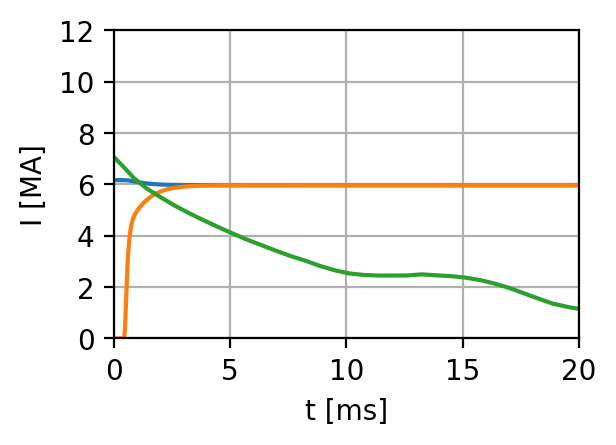

In [37]:
fig, axs = plt.subplots(1,1,figsize=(3,2),dpi=200,sharex=True)
plt.plot(t*1e3,Ip/1e6,label='$I_p$')
plt.plot(t*1e3,Ir/1e6,label='$I_r$')
plt.grid()
plt.xlabel('t [ms]')
plt.ylabel('I [MA]')
plt.ylim([0,12])
plt.yticks(np.arange(0,13,2))
#plt.xlim([0,solver.tmax*1e3])
plt.xlim([0,20])

data = np.loadtxt('Shot_18058_Current.csv', delimiter=',')
x = (data[:,0] -13.05381319457121)*1e3
y = data[:,1]
plt.plot(x, y, label='CSV data')

#plt.legend()


We can also plot the RE beam energy as a function of time

Plateau Energy [MJ] = 1.831
Average RE Energy [MeV] = 4.945


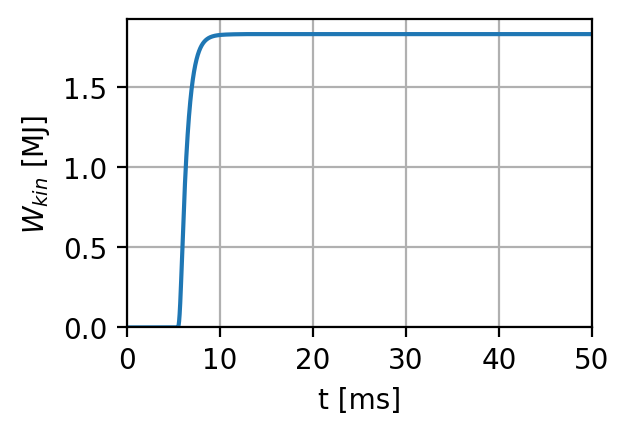

In [32]:
fig, axs = plt.subplots(1,1,figsize=(3,2),dpi=200,sharex=True)

plt.plot(t*1e3,Wk/1e6)
plt.grid()
plt.xlabel('t [ms]')
plt.ylim(ymin=0)
plt.xlim([0,solver.tmax*1e3])
axs.set_ylabel('$W_{kin}$ [MJ]')


print('Plateau Energy [MJ] = %1.3f'%(Wk[-1]/1e6))

# Estimate the average RE energy in MeV
N = Ir[-1] * (2 * np.pi * solver.R0) / (const.e * const.c)
avg_energy = Wk[-1] / N
print('Average RE Energy [MeV] = %1.3f'%(avg_energy/1e6/const.eV))


## Show detailed results

<>:24: SyntaxWarning: invalid escape sequence '\p'
<>:26: SyntaxWarning: invalid escape sequence '\p'
<>:33: SyntaxWarning: invalid escape sequence '\g'
<>:24: SyntaxWarning: invalid escape sequence '\p'
<>:26: SyntaxWarning: invalid escape sequence '\p'
<>:33: SyntaxWarning: invalid escape sequence '\g'
C:\Users\grace\AppData\Local\Temp\ipykernel_48532\1089883016.py:24: SyntaxWarning: invalid escape sequence '\p'
  axs[2, 0].plot(d['t'] * 1e3, d['E_star'], label='$E_{\parallel}/E_{CH}$')
C:\Users\grace\AppData\Local\Temp\ipykernel_48532\1089883016.py:26: SyntaxWarning: invalid escape sequence '\p'
  axs[2, 0].plot(d['t'] * 1e3, d['EoED'] * 1e5, label='$E_\parallel/E_D \\times 10^5$')
C:\Users\grace\AppData\Local\Temp\ipykernel_48532\1089883016.py:33: SyntaxWarning: invalid escape sequence '\g'
  axs[0, 1].set_ylabel('$\gamma_{ava} [s^{-1}]$')


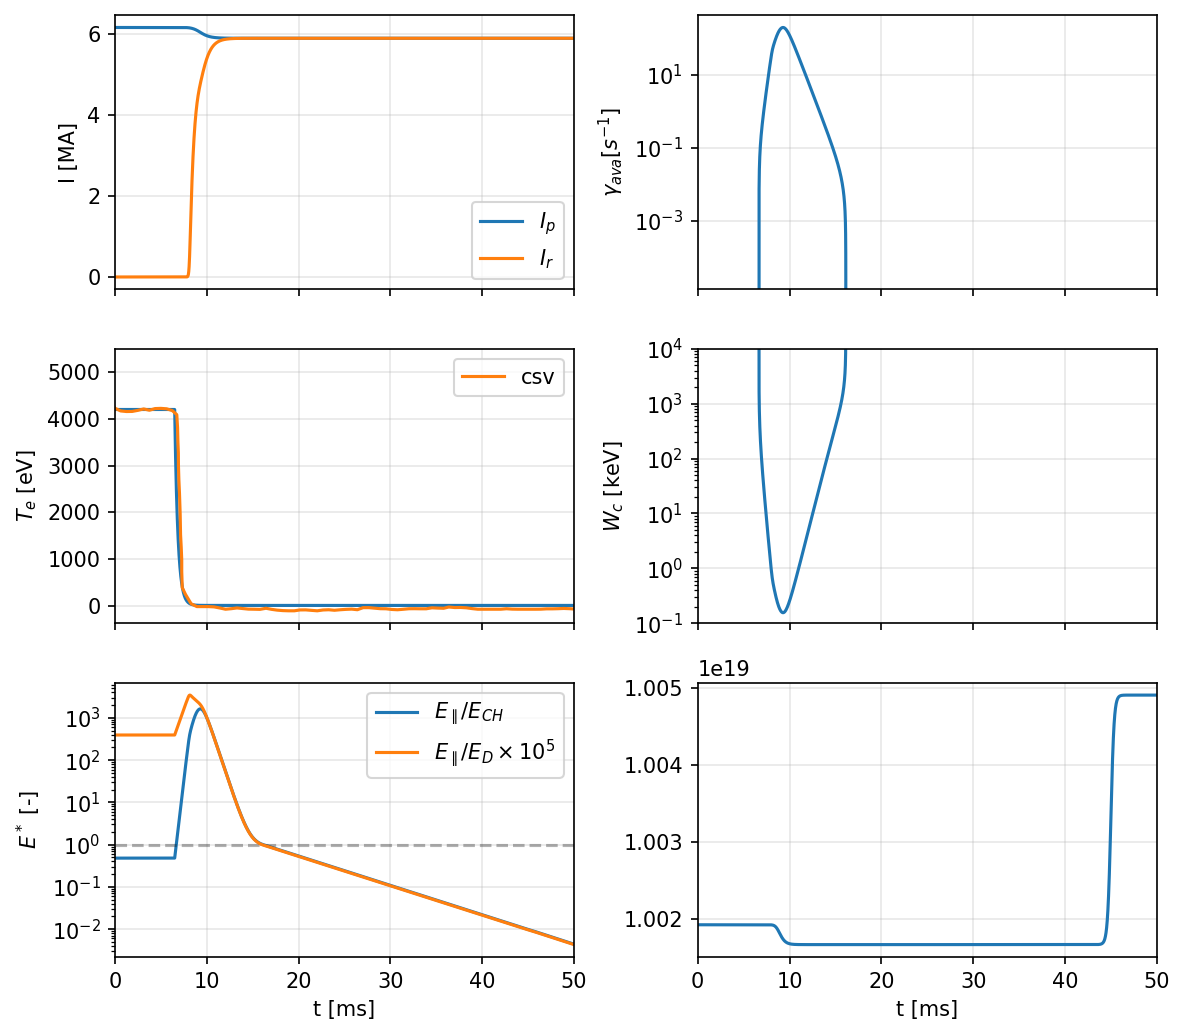

In [84]:
# Use the dictionary stored inside the solver object
d = solver.diag

fig, axs = plt.subplots(3, 2, sharex=True, figsize=(8, 7), dpi=150)

# [0,0] Currents - Compare Plasma vs Runaway
axs[0, 0].plot(d['t'] * 1e3, Ip / 1e6, label='$I_p$')
axs[0, 0].plot(d['t'] * 1e3, Ir / 1e6, label='$I_r$')
axs[0, 0].set_ylabel('I [MA]')
axs[0, 0].legend()

# [1,0] Electron Temperature
axs[1, 0].plot(d['t'] * 1e3, d['Te'])
axs[1, 0].set_ylabel('$T_e$ [eV]')
#axs[1, 0].set_yscale('log')
data = np.loadtxt('Shot_18058_Temp.csv', delimiter=',')
x = (data[:,0] -13.043814594603838)*1e3
#print(x[:5])
y = data[:,1]*1e3
axs[1, 0].plot(x, y, label="csv")
axs[1,0].legend()

# [2,0] Normalized Electric Fields
axs[2, 0].plot(d['t'] * 1e3, d['E_star'], label='$E_{\parallel}/E_{CH}$')
axs[2, 0].axhline(1, color='k', linestyle='--', alpha=0.3)
axs[2, 0].plot(d['t'] * 1e3, d['EoED'] * 1e5, label='$E_\parallel/E_D \\times 10^5$')
axs[2, 0].set_ylabel('$E^*$ [-]')
axs[2, 0].set_yscale('log')
axs[2, 0].legend()

# [0,1] Avalanche Growth Rate
axs[0, 1].plot(d['t'] * 1e3, d['gamma_ava'])
axs[0, 1].set_ylabel('$\gamma_{ava} [s^{-1}]$')
axs[0, 1].set_yscale('log')

# [1,1] Critical Energy (Recalculated for visualization)
from RE import getCriticalRunawayEnergy
import scipy.constants as const
Wc = getCriticalRunawayEnergy(d['E_star']) / const.eV
axs[1, 1].plot(d['t'] * 1e3, Wc / 1e3)
axs[1, 1].set_ylabel('$W_c$ [keV]')
axs[1, 1].set_yscale('log')
axs[1, 1].set_ylim([1e-1, 1e4])
'''
# [2,1] Primary Source Rates (Dreicer, Tritium, Compton)
axs[2, 1].plot(d['t'] * 1e3, d['SD'], label='Dreicer')
axs[2, 1].plot(d['t'] * 1e3, d['ST'], label='Tritium')
axs[2, 1].plot(d['t'] * 1e3, d['SC'], label='Compton')
axs[2, 1].set_ylabel('$dn_{RE}/dt [m^{-3}s^{-1}]$')
axs[2, 1].set_yscale('log')
axs[2, 1].set_ylim([1e6, 1e20])
axs[2, 1].legend()
'''
# [2,1] Primary Source Rates (Dreicer, Tritium, Compton)
axs[2, 1].plot(d['t'] * 1e3, d['ne'], label='Dreicer')

#axs[2, 1].set_yscale('log')
#axs[2, 1].set_ylim([0, 1e19])
#axs[2, 1].legend()

for ax in axs.flat:
    ax.grid(True, alpha=0.3)
    ax.set_xlim([0, d['t'].max() * 1e3])
    #ax.set_xlim([0, 2])

axs[2, 0].set_xlabel('t [ms]')
axs[2, 1].set_xlabel('t [ms]')
plt.tight_layout()
plt.show()

In [354]:

from RE import solver0D  

def get_nimp_standalone(t, prescibe_nz_evolution=True, t0=3.5e-4, ni=1e19, n_imp=1e16):
    """
    Calculates impurity density evolution.
    t: time in seconds 
    """
    if prescibe_nz_evolution:
        

        n0, n1, n2 = -0.76, 0.76, 0.76
        #n0, n1, n2 = -3.75, 3.76, 3.76
        out = n0 + (n1-n0) * (1 + np.tanh((t-3.5e-3)/(t0))/2 + (n2 - n1) * (1 + np.tanh((t-10.71e-3)/(1*t0)))/2)
        return out * ni
    else:
        
        return n_imp * np.ones_like(t)
# 3. Instantiate the solver
solver = solver0D()

# 4. CRITICAL: Enable diagnostics so solver.diag gets populated
solver.idiag = True 
# Change solver settings
solver.R0 = 2.96
solver.a = 1.25
solver.k = 1
solver.ni = 1e19
solver.Btor = 2.8
solver.L = 6.2e-06

solver.I0 = 7.07e6
solver.Ir0 = 0
solver.T0 = 4.2e3
solver.Tf = 5
solver.t0 = 3.5e-4

solver.n_imp = 1e-11
#solver.n_imp = solver.ni * 5
solver.Z_imp = 6
solver.A_imp = 12
solver.tmax = 100e-3
solver.tstart = 3.5e-3
solver.prescibe_nz_evolution = False
solver.iAvalanche = 0

solver.display()






 Constants:
Major radius R0 [m] = 2.960
Minor radius a [m] = 1.250
Elongation k [-] = 1.000
ni [per cubic m] = 1e+19
Inductance L [Henry] = 6.2e-06
Btor [Tesla] = 2.8

 Initial Values and TQ:
Init. Plasma Current I0 [A] = 7.07e+06
Init. RE Current Ir0 [A] = 0
Init. Temp. T0 [eV] = 4.2e+03
Final Temp. Tf [eV] = 5
Temp. decay time t0 [s] = 0.00035
Init. Vloop V0 [V] = 0
Final Vloop Vf [V] = 0

 Impurity Settings:
Added D density [per cubic m] = 1e-11
Added Impurity density [per cubic m] = 1e-11
Added Impurity Z, A [-] = 6, 12

 RE Source Settings: 

Primary: iDreicer = 1, iTritium = 0, iCompton = 0
Secondary: iAvalanche = 0

 Other Settings: 

tstart [s] = 0.0035
tmax [s] = 0.1
Zeff_scale [-] =1.0
device [-] = SPARC


<>:36: SyntaxWarning: invalid escape sequence '\p'
<>:38: SyntaxWarning: invalid escape sequence '\p'
<>:42: SyntaxWarning: invalid escape sequence '\g'
<>:36: SyntaxWarning: invalid escape sequence '\p'
<>:38: SyntaxWarning: invalid escape sequence '\p'
<>:42: SyntaxWarning: invalid escape sequence '\g'
C:\Users\grace\AppData\Local\Temp\ipykernel_48532\1571003733.py:36: SyntaxWarning: invalid escape sequence '\p'
  axs[2, 0].plot(d['t'] * 1e3, d['E_star'], label='$E_{\parallel}/E_{CH}$')
C:\Users\grace\AppData\Local\Temp\ipykernel_48532\1571003733.py:38: SyntaxWarning: invalid escape sequence '\p'
  axs[2, 0].plot(d['t'] * 1e3, d['EoED'] * 1e5, label='$E_\parallel/E_D \\times 10^5$')
C:\Users\grace\AppData\Local\Temp\ipykernel_48532\1571003733.py:42: SyntaxWarning: invalid escape sequence '\g'
  '''
C:\Users\grace\AppData\Local\Temp\ipykernel_48532\1571003733.py:78: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are 

start:  1.0004140285004104e+19 Max during TQ:  9.962842443669314e+19 Final taper: 7.71239643146651e+19


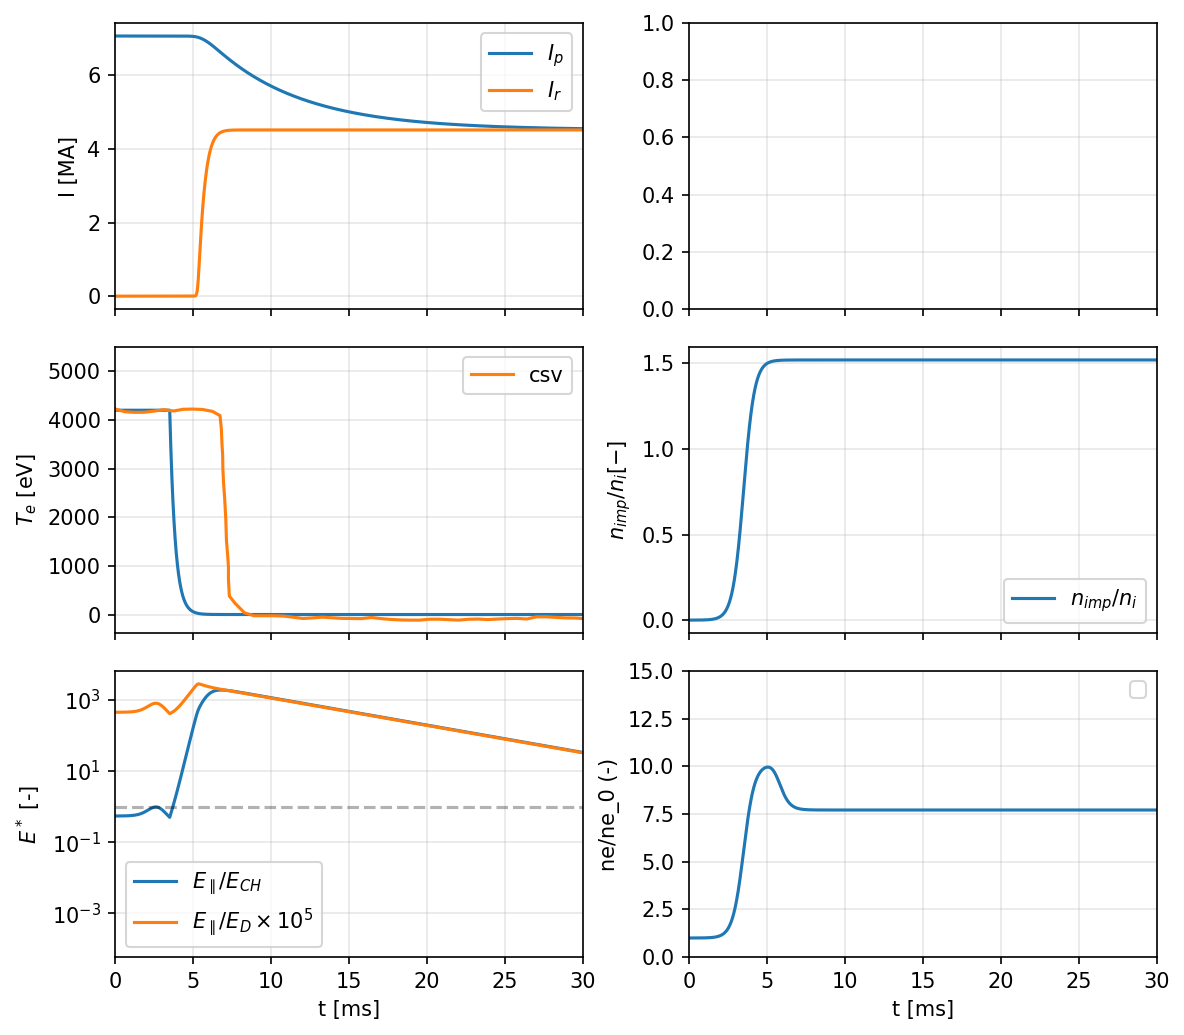

In [ ]:

solver.get_nimp = lambda t: get_nimp_standalone(
    t, 
    prescibe_nz_evolution=True, 
    t0=solver.t0 * 2,           
    ni=solver.ni,      
    n_imp=solver.n_imp         
)


t_sol, Ip, Ir, Wk = solver.solve()


d = solver.diag
fig, axs = plt.subplots(3, 2, sharex=True, figsize=(8, 7), dpi=150)

# [0,0] Currents - Compare Plasma vs Runaway
axs[0, 0].plot(d['t'] * 1e3, Ip / 1e6, label='$I_p$')
axs[0, 0].plot(d['t'] * 1e3, Ir / 1e6, label='$I_r$')
axs[0, 0].set_ylabel('I [MA]')
axs[0, 0].legend()

# [1,0] Electron Temperature
axs[1, 0].plot(d['t'] * 1e3, d['Te'])
axs[1, 0].set_ylabel('$T_e$ [eV]')
#axs[1, 0].set_yscale('log')
data = np.loadtxt('Shot_18058_Temp.csv', delimiter=',')
x = (data[:,0] -13.043814594603838)*1e3
#print(x[:5])
y = data[:,1]*1e3
axs[1, 0].plot(x, y, label="csv")
axs[1,0].legend()

# [2,0] Normalized Electric Fields
axs[2, 0].plot(d['t'] * 1e3, d['E_star'], label='$E_{\parallel}/E_{CH}$')
axs[2, 0].axhline(1, color='k', linestyle='--', alpha=0.3)
axs[2, 0].plot(d['t'] * 1e3, d['EoED'] * 1e5, label='$E_\parallel/E_D \\times 10^5$')
axs[2, 0].set_ylabel('$E^*$ [-]')
axs[2, 0].set_yscale('log')
axs[2, 0].legend()
'''
# [0,1] Avalanche Growth Rate
axs[0, 1].plot(d['t'] * 1e3, d['gamma_ava'])
axs[0, 1].set_ylabel('$\gamma_{ava} [s^{-1}]$')
axs[0, 1].set_yscale('log')
'''
# [1,1] Critical Energy (Recalculated for visualization)
'''
from RE import getCriticalRunawayEnergy
import scipy.constants as const
Wc = getCriticalRunawayEnergy(d['E_star']) / const.eV
axs[1, 1].plot(d['t'] * 1e3, Wc / 1e3)
axs[1, 1].set_ylabel('$W_c$ [keV]')
axs[1, 1].set_yscale('log')
axs[1, 1].set_ylim([1e-1, 1e4])

'''
axs[1, 1].plot(d['t'] * 1e3, d['nimp'] / solver.ni, label='$n_{imp}/n_i$')
axs[1, 1].set_ylabel('$n_{imp}/n_i [-]$')
axs[1, 1].legend()
'''
# [2,1] Primary Source Rates (Dreicer, Tritium, Compton)
axs[2, 1].plot(d['t'] * 1e3, d['SD'], label='Dreicer')
axs[2, 1].plot(d['t'] * 1e3, d['ST'], label='Tritium')
axs[2, 1].plot(d['t'] * 1e3, d['SC'], label='Compton')
axs[2, 1].set_ylabel('$dn_{RE}/dt [m^{-3}s^{-1}]$')
axs[2, 1].set_yscale('log')
axs[2, 1].set_ylim([1e6, 1e20])
axs[2, 1].legend()
'''
# [2,1] Primary Source Rates (Dreicer, Tritium, Compton)
axs[2, 1].plot(d['t'] * 1e3, d['ne']/d['ne'][0])
print("start: ",d['ne'][0], "Max during TQ: ", max(d['ne']), "Final taper:", d['ne'][-1])
axs[2, 1].set_xlabel('Time (ms)')
axs[2, 1].set_ylabel('ne/ne_0 (-)')
axs[2, 1].set_ylim(0, 15)
axs[2, 1].legend()

#axs[2, 1].set_yscale('log')
#axs[2, 1].set_ylim([0, 1e19])
#axs[2, 1].legend()

for ax in axs.flat:
    ax.grid(True, alpha=0.3)
    #ax.set_xlim([0, d['t'].max() * 1e3])
    ax.set_xlim([0, 30])

axs[2, 0].set_xlabel('t [ms]')
axs[2, 1].set_xlabel('t [ms]')
plt.tight_layout()
plt.show()

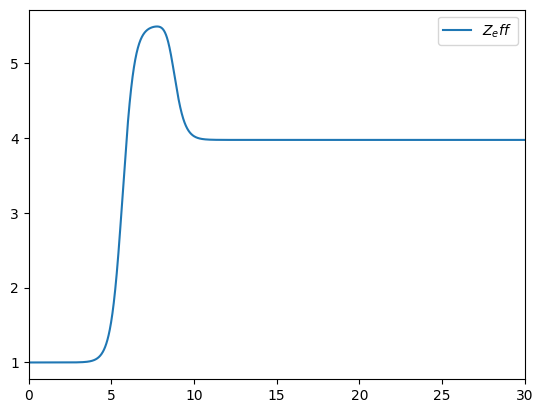

In [318]:
plt.plot(d['t'] * 1e3, d['Zeff'], label='$Z_eff$')
plt.xlim(0,30)
#plt.set_ylabel('$n_{imp}/n_i [-]$')
plt.legend()

In [ ]:
# What is ionization of Carbon as function of time
# How many electrons per cubic m is Carbon contributing to total free electron density
# What should perscribe nimp/ni be (what should curve look like) to get max ne/ne0 = 10

(0.0, 30.0)

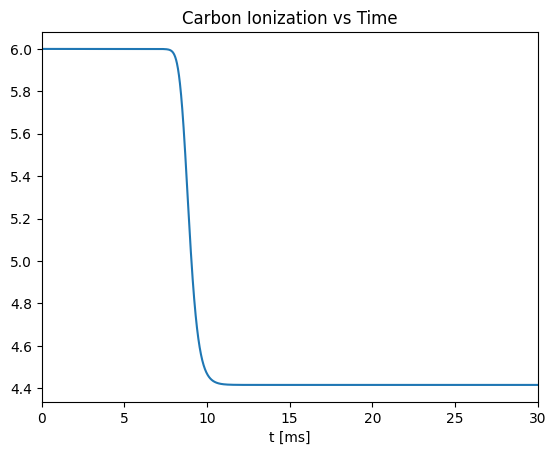

In [288]:
# What is ionization of Carbon as function of time
plt.plot(d['t'] * 1e3, d['Z'])
plt.title("Carbon Ionization vs Time")
plt.xlabel("t [ms]")
plt.xlim(0, 30)


(0.0, 30.0)

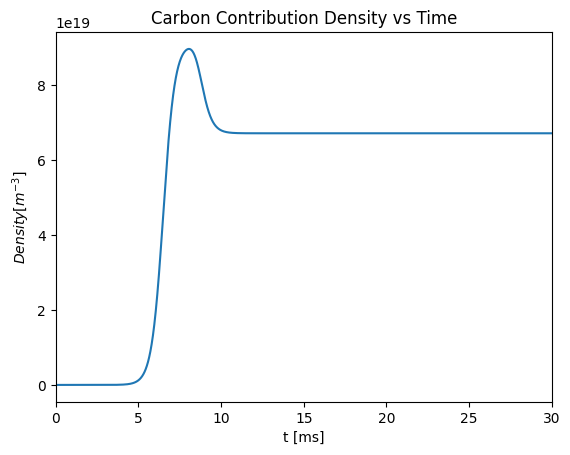

In [289]:
# How many electrons per cubic m is Carbon contributing to total free electron density
plt.plot(d['t'] * 1e3, d['Z'] * d['nimp'])
plt.title("Carbon Contribution Density vs Time")
plt.xlabel("t [ms]")
plt.ylabel('$Density [m^{-3}]$')
plt.xlim(0, 30)

(0.0, 30.0)

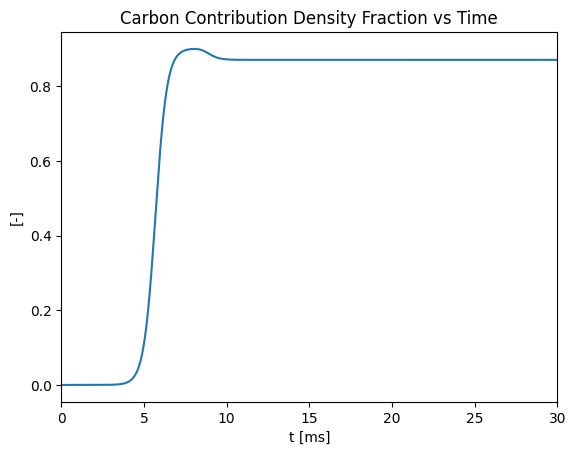

In [290]:
# How many electrons per cubic m is Carbon contributing to total free electron density
plt.plot(d['t'] * 1e3, (d['Z'] * d['nimp'])/d['ne'])
plt.title("Carbon Contribution Density Fraction vs Time")
plt.xlabel("t [ms]")
plt.ylabel('[-]')
plt.xlim(0, 30)

## Shot 18058

In [3]:
def get_nimp_standalone(t, prescibe_nz_evolution=True, t0=3.4e-4, ni=1e19, n_imp=1e16):
    """
    Calculates impurity density evolution.
    t: time in seconds 
    """
    if prescibe_nz_evolution:
        

        #n0, n1, n2 = -0.76, 0.76, 0.76
        n0, n1, n2 = -1.13, 1.13, 1.13
        out = n0 + (n1-n0) * (1 + np.tanh((t-3.5e-3)/(t0))/2 + (n2 - n1) * (1 + np.tanh((t-10.71e-3)/(1*t0)))/2)
        return out * ni
    else:
        
        return n_imp * np.ones_like(t)

solver = solver0D()


solver.idiag = True 

solver.R0 = 2.96
solver.a = 1.25
solver.k = 1
solver.ni = 1.05e19
solver.Btor = 2.8
#solver.L = 6.95e-06
solver.L = 4.3e-06

solver.I0 = 7.07e6
solver.Ir0 = 0
solver.T0 = 4.2e3
solver.Tf = 7.81
solver.t0 = 3.4e-4

solver.n_imp = 1e-11
#solver.n_imp = solver.ni * 5
solver.Z_imp = 6
solver.A_imp = 12
solver.tmax = 100e-3
solver.tstart = 3.5e-3
solver.prescibe_nz_evolution = False
solver.iAvalanche = 3
solver.iDreicer = 2

solver.display()

solver.get_nimp = lambda t: get_nimp_standalone(
    t, 
    prescibe_nz_evolution=True, 
    t0=solver.t0 * 2,           
    ni=solver.ni,      
    n_imp=solver.n_imp         
)


t_sol, Ip, Ir, Wk = solver.solve()


d = solver.diag




 Constants:
Major radius R0 [m] = 2.960
Minor radius a [m] = 1.250
Elongation k [-] = 1.000
ni [per cubic m] = 1.05e+19
Inductance L [Henry] = 4.3e-06
Btor [Tesla] = 2.8

 Initial Values and TQ:
Init. Plasma Current I0 [A] = 7.07e+06
Init. RE Current Ir0 [A] = 0
Init. Temp. T0 [eV] = 4.2e+03
Final Temp. Tf [eV] = 7.81
Temp. decay time t0 [s] = 0.00034
Init. Vloop V0 [V] = 0
Final Vloop Vf [V] = 0

 Impurity Settings:
Added D density [per cubic m] = 1e-11
Added Impurity density [per cubic m] = 1e-11
Added Impurity Z, A [-] = 6, 12

 RE Source Settings: 

Primary: iDreicer = 2, iTritium = 0, iCompton = 0
Secondary: iAvalanche = 3

 Other Settings: 

tstart [s] = 0.0035
tmax [s] = 0.1
Zeff_scale [-] =1.0
device [-] = SPARC


<>:37: SyntaxWarning: invalid escape sequence '\p'
<>:39: SyntaxWarning: invalid escape sequence '\p'
<>:46: SyntaxWarning: invalid escape sequence '\g'
<>:37: SyntaxWarning: invalid escape sequence '\p'
<>:39: SyntaxWarning: invalid escape sequence '\p'
<>:46: SyntaxWarning: invalid escape sequence '\g'
C:\Users\grace\AppData\Local\Temp\ipykernel_35060\2269561694.py:37: SyntaxWarning: invalid escape sequence '\p'
  axs[2, 0].plot(d['t'] * 1e3, d['E_star'], label='$E_{\parallel}/E_{CH}$')
C:\Users\grace\AppData\Local\Temp\ipykernel_35060\2269561694.py:39: SyntaxWarning: invalid escape sequence '\p'
  axs[2, 0].plot(d['t'] * 1e3, d['EoED'] * 1e5, label='$E_\parallel/E_D \\times 10^5$')
C:\Users\grace\AppData\Local\Temp\ipykernel_35060\2269561694.py:46: SyntaxWarning: invalid escape sequence '\g'
  axs[0, 1].set_ylabel('$\gamma_{ava} [s^{-1}]$')


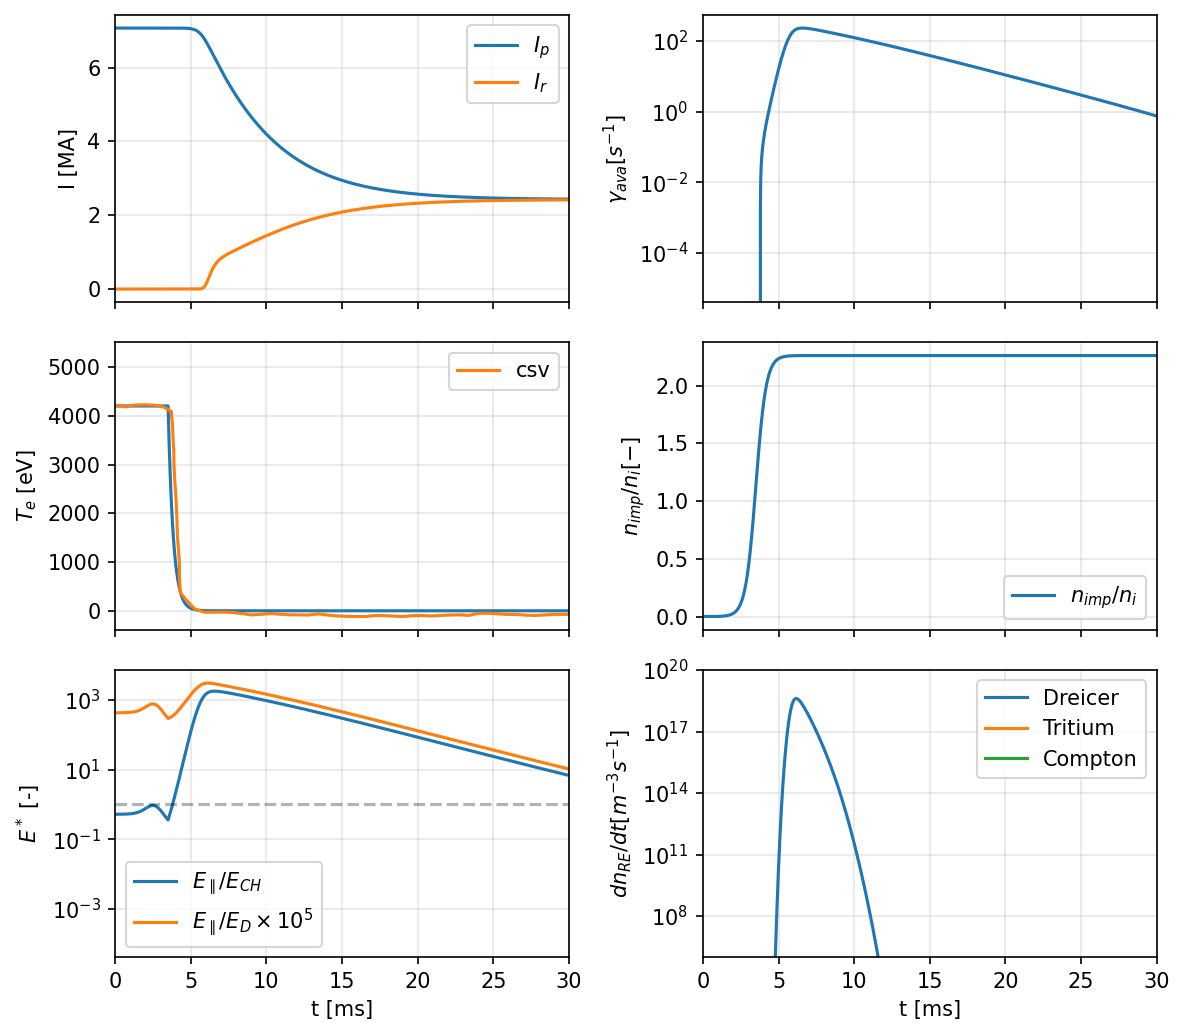

In [4]:
# 5. Monkey patch the instance method using a lambda wrapper
# This allows you to tweak your experimental constants cleanly in the notebook!
solver.get_nimp = lambda t: get_nimp_standalone(
    t, 
    prescibe_nz_evolution=True, 
    t0=solver.t0 * 2,           # Experiment with this constant
    ni=solver.ni,      # Dynamically grab 'ni' from the solver instance constants
    n_imp=solver.n_imp         # Experiment with this constant
)

# 6. Run the solver
t_sol, Ip, Ir, Wk = solver.solve()

# 7. Access the freshly generated diagnostics and plot
d = solver.diag
fig, axs = plt.subplots(3, 2, sharex=True, figsize=(8, 7), dpi=150)

# [0,0] Currents - Compare Plasma vs Runaway
axs[0, 0].plot(d['t'] * 1e3, Ip / 1e6, label='$I_p$')
axs[0, 0].plot(d['t'] * 1e3, Ir / 1e6, label='$I_r$')
axs[0, 0].set_ylabel('I [MA]')
axs[0, 0].legend()

# [1,0] Electron Temperature
axs[1, 0].plot(d['t'] * 1e3, d['Te'])
axs[1, 0].set_ylabel('$T_e$ [eV]')
#axs[1, 0].set_yscale('log')
data = np.loadtxt('Shot_18058_Temp.csv', delimiter=',')
#x = (data[:,0] -13.043814594603838)*1e3 
x = (data[:,0] -13.046834594603838)*1e3
#print(x[:5])
y = data[:,1]*1e3
axs[1, 0].plot(x, y, label="csv")
axs[1,0].legend()

# [2,0] Normalized Electric Fields
axs[2, 0].plot(d['t'] * 1e3, d['E_star'], label='$E_{\parallel}/E_{CH}$')
axs[2, 0].axhline(1, color='k', linestyle='--', alpha=0.3)
axs[2, 0].plot(d['t'] * 1e3, d['EoED'] * 1e5, label='$E_\parallel/E_D \\times 10^5$')
axs[2, 0].set_ylabel('$E^*$ [-]')
axs[2, 0].set_yscale('log')
axs[2, 0].legend()

# [0,1] Avalanche Growth Rate
axs[0, 1].plot(d['t'] * 1e3, d['gamma_ava'])
axs[0, 1].set_ylabel('$\gamma_{ava} [s^{-1}]$')
axs[0, 1].set_yscale('log')

# [1,1] Critical Energy (Recalculated for visualization)
'''
from RE import getCriticalRunawayEnergy
import scipy.constants as const
Wc = getCriticalRunawayEnergy(d['E_star']) / const.eV
axs[1, 1].plot(d['t'] * 1e3, Wc / 1e3)
axs[1, 1].set_ylabel('$W_c$ [keV]')
axs[1, 1].set_yscale('log')
axs[1, 1].set_ylim([1e-1, 1e4])

'''
axs[1, 1].plot(d['t'] * 1e3, d['nimp'] / solver.ni, label='$n_{imp}/n_i$')
axs[1, 1].set_ylabel('$n_{imp}/n_i [-]$')
axs[1, 1].legend()

# [2,1] Primary Source Rates (Dreicer, Tritium, Compton)
axs[2, 1].plot(d['t'] * 1e3, d['SD'], label='Dreicer')
axs[2, 1].plot(d['t'] * 1e3, d['ST'], label='Tritium')
axs[2, 1].plot(d['t'] * 1e3, d['SC'], label='Compton')
axs[2, 1].set_ylabel('$dn_{RE}/dt [m^{-3}s^{-1}]$')
axs[2, 1].set_yscale('log')
axs[2, 1].set_ylim([1e6, 1e20])
axs[2, 1].legend()
"""
# [2,1] Primary Source Rates (Dreicer, Tritium, Compton)
axs[2, 1].plot(d['t'] * 1e3, d['ne']/d['ne'][0])
print("start: ",d['ne'][0], "Max during TQ: ", max(d['ne']), "Final taper:", d['ne'][-1])
axs[2, 1].set_xlabel('Time (ms)')
axs[2, 1].set_ylabel('ne/ne_0 (-)')
axs[2, 1].set_ylim(0, 15)
axs[2, 1].legend()
"""
#axs[2, 1].set_yscale('log')
#axs[2, 1].set_ylim([0, 1e19])
#axs[2, 1].legend()

for ax in axs.flat:
    ax.grid(True, alpha=0.3)
    #ax.set_xlim([0, d['t'].max() * 1e3])
    ax.set_xlim([0, 30])

axs[2, 0].set_xlabel('t [ms]')
axs[2, 1].set_xlabel('t [ms]')
plt.tight_layout()
plt.show()

2.421148169148963


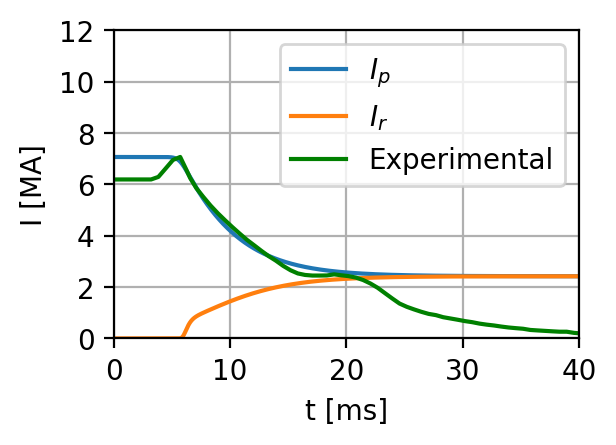

In [5]:
fig, axs = plt.subplots(1,1,figsize=(3,2),dpi=200,sharex=True)
plt.plot(t_sol*1e3,Ip/1e6,label='$I_p$')
print(Ip[-1]/1e6)
plt.plot(t_sol*1e3,Ir/1e6,label='$I_r$')
#plt.plot(t*1e3,Ir/1e6,label='$I_r$')
plt.grid()
plt.xlabel('t [ms]')
plt.ylabel('I [MA]')
plt.ylim([0,10])
plt.yticks(np.arange(0,13,2))
#plt.xlim([0,solver.tmax*1e3])
plt.xlim([0,40])

data = np.loadtxt('Shot_18058_Current.csv', delimiter=',')
#x = (data[:,0] -13.05381319457121)*1e3
x = (data[:,0] -13.04811319457121)*1e3
y = data[:,1]
plt.plot(x, y, label='Experimental', color='g')
plt.legend()

#plt.legend()


Plateau Energy [MJ] = 24.628
Average RE Energy [MeV] = 163.970


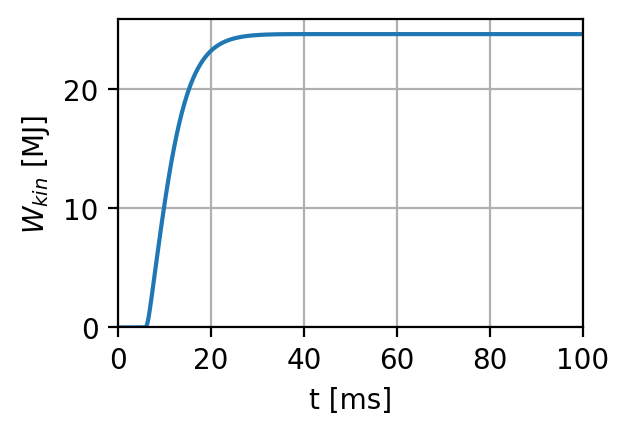

In [6]:
fig, axs = plt.subplots(1,1,figsize=(3,2),dpi=200,sharex=True)

plt.plot(t_sol*1e3,Wk/1e6)
plt.grid()
plt.xlabel('t [ms]')
plt.ylim(ymin=0)
plt.xlim([0,solver.tmax*1e3])
axs.set_ylabel('$W_{kin}$ [MJ]')


print('Plateau Energy [MJ] = %1.3f'%(Wk[-1]/1e6))

# Estimate the average RE energy in MeV
N = Ir[-1] * (2 * np.pi * solver.R0) / (const.e * const.c)
avg_energy = Wk[-1] / N
print('Average RE Energy [MeV] = %1.3f'%(avg_energy/1e6/const.eV))


In [7]:
print(Wk[-1])
print(N)

24628469.150294628
9.374795451667904e+17


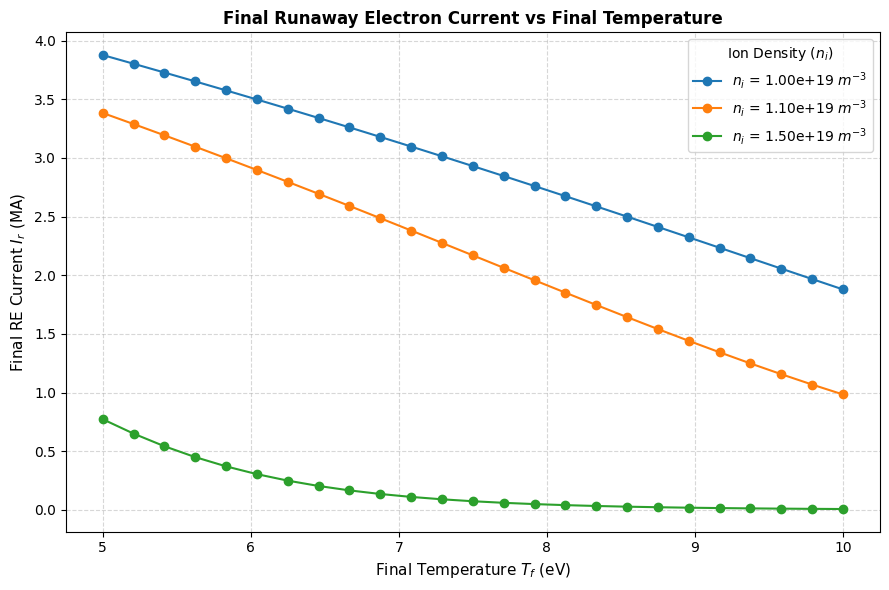

In [ ]:
Tf_range = np.linspace(5, 10, 25)  
ni_values = [1e19, 1.1e19, 1.5e19]

plt.figure(figsize=(9, 6))


for ni_val in ni_values:
    final_Ir_list = []
    
    
    for tf_val in Tf_range:
        
        solver = solver0D()
        solver.idiag = True 
        
        solver.R0 = 2.96
        solver.a = 1.25
        solver.k = 1
        solver.Btor = 2.8
        solver.L = 4.3e-06
        
        
        solver.I0 = 7.07e6
        solver.Ir0 = 0
        solver.T0 = 4.2e3
        solver.t0 = 3.4e-4
        solver.tmax = 100e-3
        solver.tstart = 3.5e-3
        
        
        solver.n_imp = 1e-11
        solver.Z_imp = 6
        solver.A_imp = 12
        solver.prescibe_nz_evolution = False
        solver.iAvalanche = 3
        solver.iDreicer = 2
        
        solver.ni = ni_val
        solver.Tf = tf_val
        
        # Apply your custom notebook patch function
        solver.get_nimp = lambda t: get_nimp_standalone(
            t, 
            prescibe_nz_evolution=True, 
            t0=solver.t0 * 2,          
            ni=solver.ni,      
            n_imp=solver.n_imp         
        )
        
        
        t_sol, Ip, Ir, Wk = solver.solve()
        
        final_Ir_list.append(Ir[-1] / 1e6) 
        

    plt.plot(Tf_range, final_Ir_list, marker='o', label=f'$n_i$ = {ni_val:.2e} $m^{{-3}}$')


plt.title('Final Runaway Electron Current vs Final Temperature', fontsize=12, fontweight='bold')
plt.xlabel('Final Temperature $T_f$ (eV)', fontsize=11)
plt.ylabel('Final RE Current $I_r$ (MA)', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='best')

plt.tight_layout()
plt.show()

[-22518.82498875 -22519.83404541 -22521.88195801 -22523.99206543
 -22526.16461182 -22528.39746094 -22530.69250488 -22533.05212402
 -22535.47894287 -22537.97521973 -22540.5435791  -22543.18652344
 -22545.90643311 -22548.70587158 -22551.58721924 -22554.55310059
 -22557.60583496 -22560.7479248  -22563.98187256 -22567.31018066]
[7070000.         7069999.77478923 7069999.54955827 7069999.32430654
 7069999.09903338 7069998.87373819 7069998.64842037 7069998.42307928
 7069998.19771426 7069997.97232462 7069997.74690967 7069997.52146867
 7069997.29600085 7069997.07050544 7069996.84498163 7069996.61942859
 7069996.39384546 7069996.16823135 7069995.94258537 7069995.71690658]
[0.00000000e+00 1.00010001e-05 2.00020002e-05 3.00030003e-05
 4.00040004e-05 5.00050005e-05 6.00060006e-05 7.00070007e-05
 8.00080008e-05 9.00090009e-05 1.00010001e-04 1.10011001e-04
 1.20012001e-04 1.30013001e-04 1.40014001e-04 1.50015002e-04
 1.60016002e-04 1.70017002e-04 1.80018002e-04 1.90019002e-04]


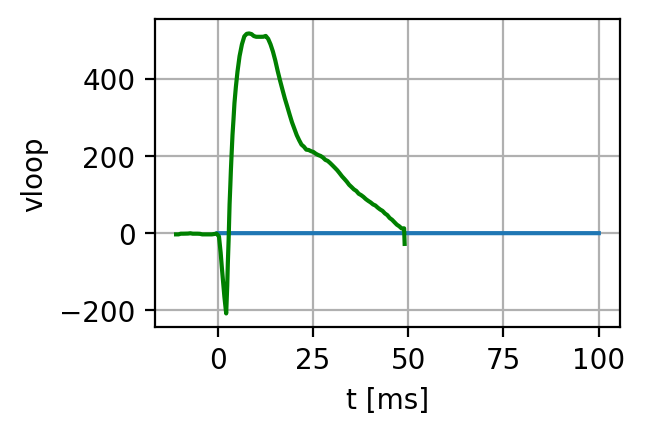

In [712]:
fig, axs = plt.subplots(1,1,figsize=(3,2),dpi=200,sharex=True)
# Epar * 2*pi*R + L * dIp/dt
dIpdt = np.gradient(Ip, t_sol)
#print(solver.L)
print(dIpdt[:20])
print(Ip[:20])
print(t_sol[:20])
plt.plot(t_sol*1e3,d["Epar"] * 2*np.pi*solver.R0 + solver.L * dIpdt,label='$I_p$')
#print(Ip[-1]/1e6)
#plt.plot(t*1e3,Ir/1e6,label='$I_r$')
plt.grid()
plt.xlabel('t [ms]')
plt.ylabel('vloop')
#plt.ylim([0,10])
#plt.yticks(np.arange(0,13,2))
#plt.xlim([0,solver.tmax*1e3])
#plt.xlim([0,40])

data = np.loadtxt('Shot_18058_Vloop.csv', delimiter=',')
#x = (data[:,0] -13.05381319457121)*1e3
x = (data[:,0] -13.05111319457121)*1e3
y = data[:,1]
plt.plot(x, y, label='CSV data', color='g')

#plt.legend()


4.58e-06
[-22518.82498875 -22519.83404541 -22521.88195801 -22523.99206543
 -22526.16461182 -22528.39746094 -22530.69250488 -22533.05212402
 -22535.47894287 -22537.97521973 -22540.5435791  -22543.18652344
 -22545.90643311 -22548.70587158 -22551.58721924 -22554.55310059
 -22557.60583496 -22560.7479248  -22563.98187256 -22567.31018066]
[7070000.         7069999.77478923 7069999.54955827 7069999.32430654
 7069999.09903338 7069998.87373819 7069998.64842037 7069998.42307928
 7069998.19771426 7069997.97232462 7069997.74690967 7069997.52146867
 7069997.29600085 7069997.07050544 7069996.84498163 7069996.61942859
 7069996.39384546 7069996.16823135 7069995.94258537 7069995.71690658]
[0.00000000e+00 1.00010001e-05 2.00020002e-05 3.00030003e-05
 4.00040004e-05 5.00050005e-05 6.00060006e-05 7.00070007e-05
 8.00080008e-05 9.00090009e-05 1.00010001e-04 1.10011001e-04
 1.20012001e-04 1.30013001e-04 1.40014001e-04 1.50015002e-04
 1.60016002e-04 1.70017002e-04 1.80018002e-04 1.90019002e-04]


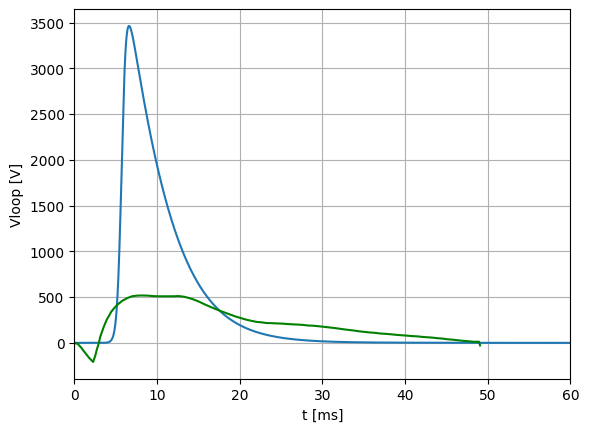

In [711]:
print(solver.L)
print(dIpdt[:20])
print(Ip[:20])
print(t_sol[:20])
plt.plot(t_sol*1e3,d["Epar"] * 2*np.pi*solver.R0 ,label='$I_p$')
#print(Ip[-1]/1e6)
#plt.plot(t*1e3,Ir/1e6,label='$I_r$')
plt.grid()
plt.xlabel('t [ms]')
plt.ylabel('Vloop [V]')
#plt.ylim([0,10])
#plt.yticks(np.arange(0,13,2))
#plt.xlim([0,solver.tmax*1e3])
plt.xlim([0,60])

data = np.loadtxt('Shot_18058_Vloop.csv', delimiter=',')
#x = (data[:,0] -13.05381319457121)*1e3
x = (data[:,0] -13.05111319457121)*1e3
y = data[:,1]
plt.plot(x, y, label='CSV data', color='g')

#plt.legend()


4.58e-06
[-22518.82498875 -22519.83404541 -22521.88195801 -22523.99206543
 -22526.16461182 -22528.39746094 -22530.69250488 -22533.05212402
 -22535.47894287 -22537.97521973 -22540.5435791  -22543.18652344
 -22545.90643311 -22548.70587158 -22551.58721924 -22554.55310059
 -22557.60583496 -22560.7479248  -22563.98187256 -22567.31018066]
[7070000.         7069999.77478923 7069999.54955827 7069999.32430654
 7069999.09903338 7069998.87373819 7069998.64842037 7069998.42307928
 7069998.19771426 7069997.97232462 7069997.74690967 7069997.52146867
 7069997.29600085 7069997.07050544 7069996.84498163 7069996.61942859
 7069996.39384546 7069996.16823135 7069995.94258537 7069995.71690658]
0.1


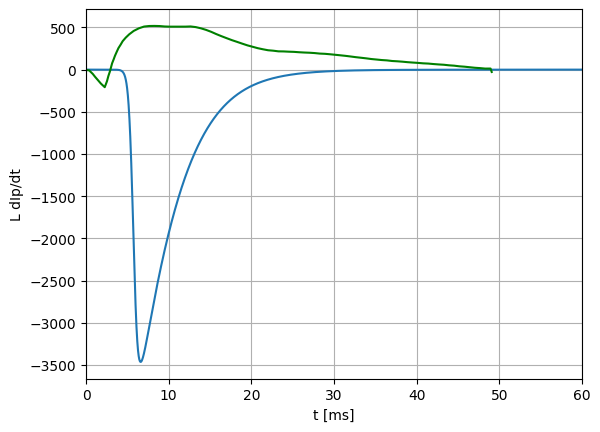

In [710]:
# Epar * 2*pi*R + L * dIp/dt
dIpdt = np.gradient(Ip, t_sol)
print(solver.L)
print(dIpdt[:20])
print(Ip[:20])
print(t_sol[-1])
plt.plot(t_sol*1e3, solver.L * dIpdt)
#print(Ip[-1]/1e6)
#plt.plot(t*1e3,Ir/1e6,label='$I_r$')
plt.grid()
plt.xlabel('t [ms]')
plt.ylabel('L dIp/dt')
#plt.ylim([0,10])
#plt.yticks(np.arange(0,13,2))
#plt.xlim([0,solver.tmax*1e3])
plt.xlim([0,60])

data = np.loadtxt('Shot_18058_Vloop.csv', delimiter=',')
#x = (data[:,0] -13.05381319457121)*1e3
x = (data[:,0] -13.05111319457121)*1e3
y = data[:,1]
plt.plot(x, y, label='CSV data', color='g')

#plt.legend()


## Shot 19548 (SN)

In [673]:
def get_nimp_standalone(t, prescibe_nz_evolution=True, t0=3.4e-4, ni=1e19, n_imp=1e16):
    """
    Calculates impurity density evolution.
    t: time in seconds 
    """
    if prescibe_nz_evolution:
        

        n0, n1, n2 = -0.35, 0.35, 0.35
        #n0, n1, n2 = -0.76, 0.76, 0.76
        out = n0 + (n1-n0) * (1 + np.tanh((t-3.5e-3)/(t0))/2 + (n2 - n1) * (1 + np.tanh((t-10.71e-3)/(1*t0)))/2)
        
        return out * ni
    else:
        
        return n_imp * np.ones_like(t)

solver = solver0D()

'''n0, n1, n2 = -1.27, 1.27, 1.27
k = 1.7
solver.ni = 1.20e19
solver.L = 3.80e-06
solver.Tf = 8
'''

solver.idiag = True 

solver.R0 = 2.96
solver.a = 1.25
solver.k = 1.6
solver.ni = 0.95e19
solver.Btor = 2.8
#solver.L = 6.95e-06
solver.L = 4.98e-06

solver.I0 = 3.49e6
#solver.I0 = 7e6
solver.Ir0 = 0
solver.T0 = 4.2e3
solver.Tf = 5.51
solver.t0 = 3.4e-4


solver.n_imp = 1e-11
#solver.n_imp = solver.ni * 5
solver.Z_imp = 6
solver.A_imp = 12
solver.tmax = 200e-3
solver.tstart = 3.5e-3
solver.prescibe_nz_evolution = False
solver.iAvalanche = 3
solver.iDreicer = 2

solver.display()

solver.get_nimp = lambda t: get_nimp_standalone(
    t, 
    prescibe_nz_evolution=True, 
    t0=solver.t0 * 2,           
    ni=solver.ni,      
    n_imp=solver.n_imp         
)


t_sol, Ip, Ir, Wk = solver.solve()


d = solver.diag




 Constants:
Major radius R0 [m] = 2.960
Minor radius a [m] = 1.250
Elongation k [-] = 1.600
ni [per cubic m] = 9.5e+18
Inductance L [Henry] = 4.98e-06
Btor [Tesla] = 2.8

 Initial Values and TQ:
Init. Plasma Current I0 [A] = 3.49e+06
Init. RE Current Ir0 [A] = 0
Init. Temp. T0 [eV] = 4.2e+03
Final Temp. Tf [eV] = 5.51
Temp. decay time t0 [s] = 0.00034
Init. Vloop V0 [V] = 0
Final Vloop Vf [V] = 0

 Impurity Settings:
Added D density [per cubic m] = 1e-11
Added Impurity density [per cubic m] = 1e-11
Added Impurity Z, A [-] = 6, 12

 RE Source Settings: 

Primary: iDreicer = 2, iTritium = 0, iCompton = 0
Secondary: iAvalanche = 3

 Other Settings: 

tstart [s] = 0.0035
tmax [s] = 0.2
Zeff_scale [-] =1.0
device [-] = SPARC


<>:22: SyntaxWarning: invalid escape sequence '\p'
<>:24: SyntaxWarning: invalid escape sequence '\p'
<>:31: SyntaxWarning: invalid escape sequence '\g'
<>:22: SyntaxWarning: invalid escape sequence '\p'
<>:24: SyntaxWarning: invalid escape sequence '\p'
<>:31: SyntaxWarning: invalid escape sequence '\g'
C:\Users\grace\AppData\Local\Temp\ipykernel_27336\126409289.py:22: SyntaxWarning: invalid escape sequence '\p'
  axs[2, 0].plot(d['t'] * 1e3, d['E_star'], label='$E_{\parallel}/E_{CH}$')
C:\Users\grace\AppData\Local\Temp\ipykernel_27336\126409289.py:24: SyntaxWarning: invalid escape sequence '\p'
  axs[2, 0].plot(d['t'] * 1e3, d['EoED'] * 1e5, label='$E_\parallel/E_D \\times 10^5$')
C:\Users\grace\AppData\Local\Temp\ipykernel_27336\126409289.py:31: SyntaxWarning: invalid escape sequence '\g'
  axs[0, 1].set_ylabel('$\gamma_{ava} [s^{-1}]$')


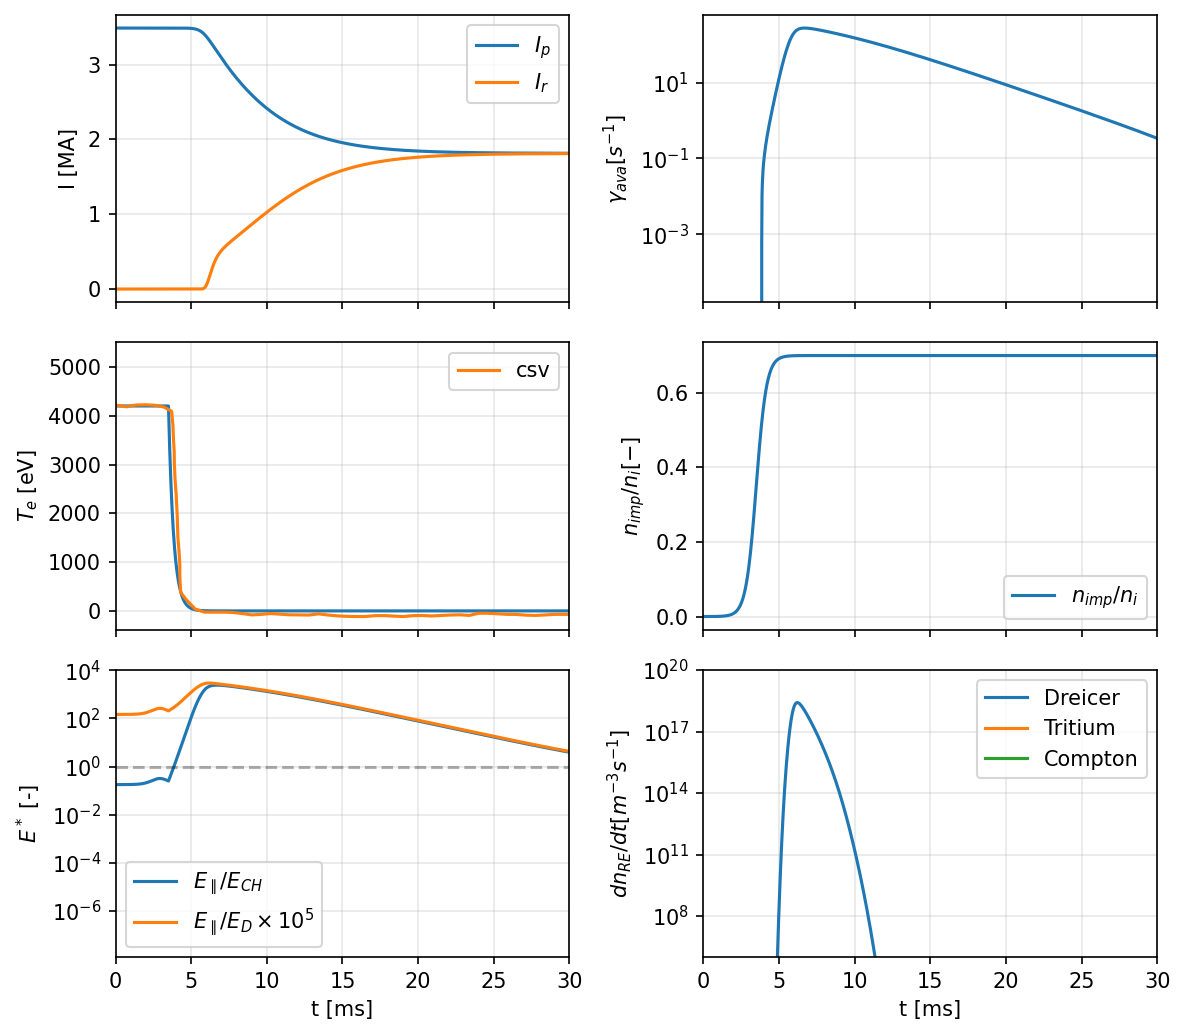

In [676]:


fig, axs = plt.subplots(3, 2, sharex=True, figsize=(8, 7), dpi=150)

# [0,0] Currents - Compare Plasma vs Runaway
axs[0, 0].plot(d['t'] * 1e3, Ip / 1e6, label='$I_p$')
axs[0, 0].plot(d['t'] * 1e3, Ir / 1e6, label='$I_r$')
axs[0, 0].set_ylabel('I [MA]')
axs[0, 0].legend()

# [1,0] Electron Temperature
axs[1, 0].plot(d['t'] * 1e3, d['Te'])
axs[1, 0].set_ylabel('$T_e$ [eV]')
#axs[1, 0].set_yscale('log')
data = np.loadtxt('Shot_18058_Temp.csv', delimiter=',')
#x = (data[:,0] -13.043814594603838)*1e3 
x = (data[:,0] -13.046834594603838)*1e3
#print(x[:5])
y = data[:,1]*1e3
axs[1, 0].plot(x, y, label="csv")
axs[1,0].legend()

# [2,0] Normalized Electric Fields
axs[2, 0].plot(d['t'] * 1e3, d['E_star'], label='$E_{\parallel}/E_{CH}$')
axs[2, 0].axhline(1, color='k', linestyle='--', alpha=0.3)
axs[2, 0].plot(d['t'] * 1e3, d['EoED'] * 1e5, label='$E_\parallel/E_D \\times 10^5$')
axs[2, 0].set_ylabel('$E^*$ [-]')
axs[2, 0].set_yscale('log')
axs[2, 0].legend()

# [0,1] Avalanche Growth Rate
axs[0, 1].plot(d['t'] * 1e3, d['gamma_ava'])
axs[0, 1].set_ylabel('$\gamma_{ava} [s^{-1}]$')
axs[0, 1].set_yscale('log')

# [1,1] Critical Energy (Recalculated for visualization)
'''
from RE import getCriticalRunawayEnergy
import scipy.constants as const
Wc = getCriticalRunawayEnergy(d['E_star']) / const.eV
axs[1, 1].plot(d['t'] * 1e3, Wc / 1e3)
axs[1, 1].set_ylabel('$W_c$ [keV]')
axs[1, 1].set_yscale('log')
axs[1, 1].set_ylim([1e-1, 1e4])

'''
axs[1, 1].plot(d['t'] * 1e3, d['nimp'] / solver.ni, label='$n_{imp}/n_i$')
axs[1, 1].set_ylabel('$n_{imp}/n_i [-]$')
axs[1, 1].legend()

# [2,1] Primary Source Rates (Dreicer, Tritium, Compton)
axs[2, 1].plot(d['t'] * 1e3, d['SD'], label='Dreicer')
axs[2, 1].plot(d['t'] * 1e3, d['ST'], label='Tritium')
axs[2, 1].plot(d['t'] * 1e3, d['SC'], label='Compton')
axs[2, 1].set_ylabel('$dn_{RE}/dt [m^{-3}s^{-1}]$')
axs[2, 1].set_yscale('log')
axs[2, 1].set_ylim([1e6, 1e20])
axs[2, 1].legend()
'''
# [2,1] Primary Source Rates (Dreicer, Tritium, Compton)
axs[2, 1].plot(d['t'] * 1e3, d['ne']/d['ne'][0])
print("start: ",d['ne'][0], "Max during TQ: ", max(d['ne']), "Final taper:", d['ne'][-1])
axs[2, 1].set_xlabel('Time (ms)')
axs[2, 1].set_ylabel('ne/ne_0 (-)')
axs[2, 1].set_ylim(0, 15)
axs[2, 1].legend()
'''
#axs[2, 1].set_yscale('log')
#axs[2, 1].set_ylim([0, 1e19])
#axs[2, 1].legend()

for ax in axs.flat:
    ax.grid(True, alpha=0.3)
    #ax.set_xlim([0, d['t'].max() * 1e3])
    ax.set_xlim([0, 30])

axs[2, 0].set_xlabel('t [ms]')
axs[2, 1].set_xlabel('t [ms]')
plt.tight_layout()
plt.show()

1.8094158752098375


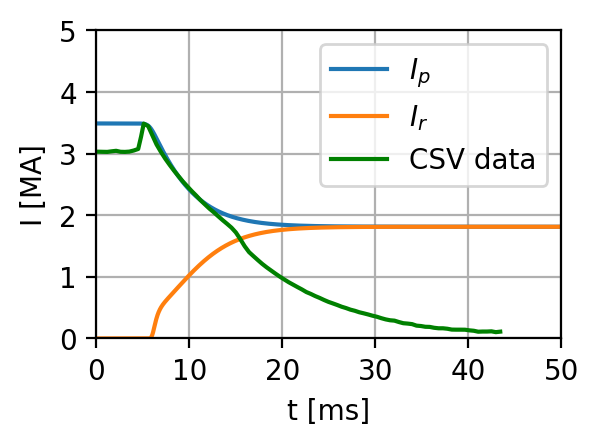

In [677]:
fig, axs = plt.subplots(1,1,figsize=(3,2),dpi=200,sharex=True)
plt.plot(t_sol*1e3,Ip/1e6,label='$I_p$')
print(Ip[-1]/1e6)
plt.plot(t_sol*1e3,Ir/1e6,label='$I_r$')
plt.grid()
plt.xlabel('t [ms]')
plt.ylabel('I [MA]')
plt.ylim([0,5])
#plt.yticks(np.arange(0,13,2))
#plt.xlim([0,solver.tmax*1e3])
plt.xlim([0,50])

data = np.loadtxt('Shot_19548_Current.csv', delimiter=',')
#x = (data[:,0] -13.05381319457121)*1e3
x = (data[:,0] -13.355577873439327)*1e3
y = data[:,1]
plt.plot(x, y, label='CSV data', color='g')

plt.legend()


Plateau Energy [MJ] = 7.157
Average RE Energy [MeV] = 63.637


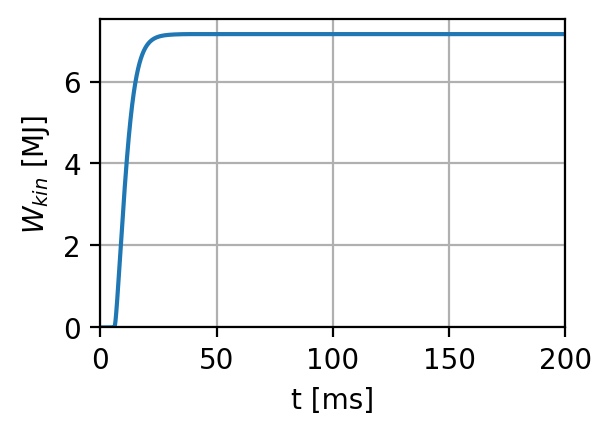

In [678]:
fig, axs = plt.subplots(1,1,figsize=(3,2),dpi=200,sharex=True)

plt.plot(t_sol*1e3,Wk/1e6)
plt.grid()
plt.xlabel('t [ms]')
plt.ylim(ymin=0)
plt.xlim([0,solver.tmax*1e3])
axs.set_ylabel('$W_{kin}$ [MJ]')


print('Plateau Energy [MJ] = %1.3f'%(Wk[-1]/1e6))

# Estimate the average RE energy in MeV
N = Ir[-1] * (2 * np.pi * solver.R0) / (const.e * const.c)
avg_energy = Wk[-1] / N
print('Average RE Energy [MeV] = %1.3f'%(avg_energy/1e6/const.eV))

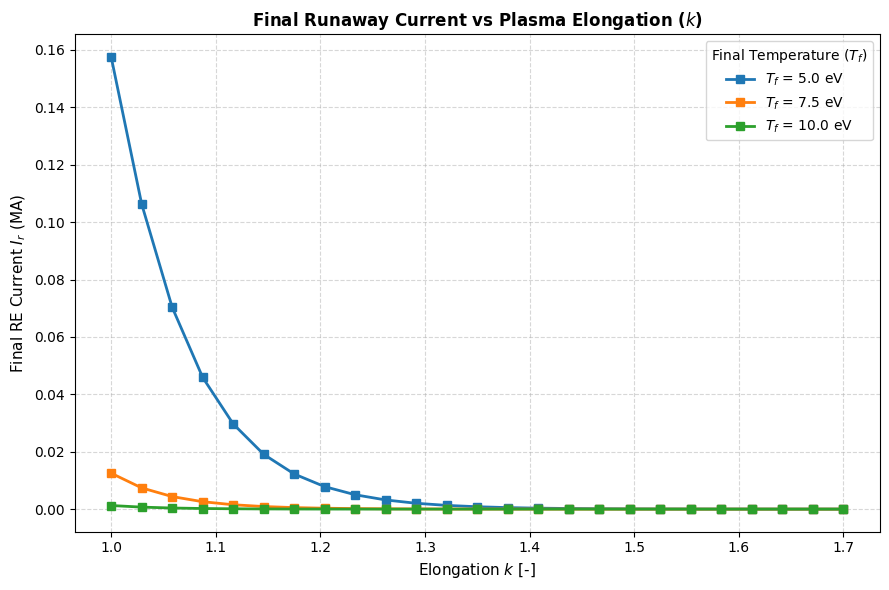

In [145]:

k_range = np.linspace(1, 1.7, 25)  
Tf_values = [5.0, 7.5, 10.0]        

plt.figure(figsize=(9, 6))


for tf_val in Tf_values:
    final_Ir_list = []
    
    
    for k_val in k_range:
        
        solver = solver0D()
        solver.idiag = True 
        
        
        solver.R0 = 2.96
        solver.a = 1.25
        solver.Btor = 2.8
        solver.L = 4.58e-06
        
        
        solver.I0 = 3.49e6
        solver.Ir0 = 0
        solver.T0 = 4.2e3
        solver.t0 = 3.5e-4
        solver.tmax = 200e-3
        solver.tstart = 3.5e-3
        
        solver.n_imp = 1e-11
        solver.Z_imp = 6
        solver.A_imp = 12
        solver.prescibe_nz_evolution = False
        solver.iAvalanche = 3
        solver.iDreicer = 2
        
        solver.ni = 1.07e19
        solver.k = k_val
        solver.Tf = tf_val
        
     
        solver.get_nimp = lambda t: get_nimp_standalone(
            t, 
            prescibe_nz_evolution=True, 
            t0=solver.t0 * 2,          
            ni=solver.ni,      
            n_imp=solver.n_imp         
        )
        
        
        t_sol, Ip, Ir, Wk = solver.solve()
        
    
        final_Ir_list.append(Ir[-1] / 1e6) 
        

    plt.plot(k_range, final_Ir_list, marker='s', lw=2, label=f'$T_f$ = {tf_val:.1f} eV')

plt.title('Final Runaway Current vs Plasma Elongation ($k$)', fontsize=12, fontweight='bold')
plt.xlabel('Elongation $k$ [-]', fontsize=11)
plt.ylabel('Final RE Current $I_r$ (MA)', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(title='Final Temperature ($T_f$)', loc='best')

plt.tight_layout()
plt.show()

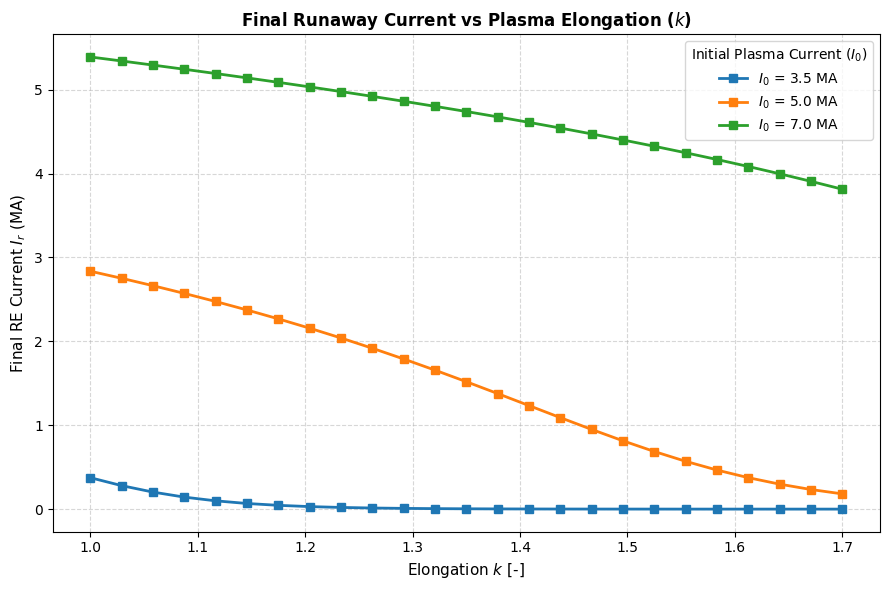

In [151]:

k_range = np.linspace(1, 1.7, 25)  
I0_values = [3.5e6, 5e6, 7e6]        

plt.figure(figsize=(9, 6))


for I0_val in I0_values:
    final_Ir_list = []
    
    
    for k_val in k_range:
        
        solver = solver0D()
        solver.idiag = True 
        
        
        solver.R0 = 2.96
        solver.a = 1.25
        solver.Btor = 2.8
        solver.L = 4.58e-06
        
        
        solver.I0 = I0_val
        solver.Ir0 = 0
        solver.T0 = 4.2e3
        solver.t0 = 3.5e-4
        solver.tmax = 200e-3
        solver.tstart = 3.5e-3
        
        solver.n_imp = 1e-11
        solver.Z_imp = 6
        solver.A_imp = 12
        solver.prescibe_nz_evolution = False
        solver.iAvalanche = 3
        solver.iDreicer = 2
        
        solver.ni = 1e19
        solver.k = k_val
        solver.Tf = 5
        
     
        solver.get_nimp = lambda t: get_nimp_standalone(
            t, 
            prescibe_nz_evolution=True, 
            t0=solver.t0 * 2,          
            ni=solver.ni,      
            n_imp=solver.n_imp         
        )
        
        
        t_sol, Ip, Ir, Wk = solver.solve()
        
    
        final_Ir_list.append(Ir[-1] / 1e6) 
        

    plt.plot(k_range, final_Ir_list, marker='s', lw=2, label=f'$I_0$ = {I0_val/1e6} MA')

plt.title('Final Runaway Current vs Plasma Elongation ($k$)', fontsize=12, fontweight='bold')
plt.xlabel('Elongation $k$ [-]', fontsize=11)
plt.ylabel('Final RE Current $I_r$ (MA)', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(title='Initial Plasma Current ($I_0$)', loc='best')

plt.tight_layout()
plt.show()

## Shot 20909 (Be lim)

In [641]:
def get_nimp_standalone(t, prescibe_nz_evolution=True, t0=3.5e-4, ni=1e19, n_imp=1e16):
    """
    Calculates impurity density evolution.
    t: time in seconds 
    """
    if prescibe_nz_evolution:
        

        n0, n1, n2 = -0.80, 0.36, 0.36
        #n0, n1, n2 = -20.27, 20.27, 20.27
        out = n0 + (n1-n0) * (1 + np.tanh((t-6.5e-3)/(t0))/2 + (n2 - n1) * (1 + np.tanh((t-40.71e-3)/(1*t0)))/2)
        return out * ni
    else:
        
        return n_imp * np.ones_like(t)

solver = solver0D()


solver.idiag = True 

solver.R0 = 2.96
solver.a = 1.25
solver.k = 1.0
solver.ni = 1.07e19
solver.Btor = 2.8
#solver.L = 6.95e-06
solver.L = 4.5e-06

solver.I0 = 5.74e6
solver.Ir0 = 0
solver.T0 = 2.33e3
solver.Tf = 30 # Supposed to be 20-30 eV at "higher resolution" but extracted data from plot looks 10x higher than that
solver.t0 = 4.5e-3

solver.n_imp = 1e-11
#solver.n_imp = solver.ni * 5
solver.Z_imp = 4
solver.A_imp = 9
solver.tmax = 1000e-3
solver.tstart = 6.5e-3
solver.prescibe_nz_evolution = False
solver.iAvalanche = 3
solver.iDreicer = 2

solver.display()

solver.get_nimp = lambda t: get_nimp_standalone(
    t, 
    prescibe_nz_evolution=True, 
    t0=solver.t0 * 2,           
    ni=solver.ni,      
    n_imp=solver.n_imp         
)


t_sol, Ip, Ir, Wk = solver.solve()


d = solver.diag




 Constants:
Major radius R0 [m] = 2.960
Minor radius a [m] = 1.250
Elongation k [-] = 1.000
ni [per cubic m] = 1.07e+19
Inductance L [Henry] = 4.5e-06
Btor [Tesla] = 2.8

 Initial Values and TQ:
Init. Plasma Current I0 [A] = 5.74e+06
Init. RE Current Ir0 [A] = 0
Init. Temp. T0 [eV] = 2.33e+03
Final Temp. Tf [eV] = 30
Temp. decay time t0 [s] = 0.0045
Init. Vloop V0 [V] = 0
Final Vloop Vf [V] = 0

 Impurity Settings:
Added D density [per cubic m] = 1e-11
Added Impurity density [per cubic m] = 1e-11
Added Impurity Z, A [-] = 4, 9

 RE Source Settings: 

Primary: iDreicer = 2, iTritium = 0, iCompton = 0
Secondary: iAvalanche = 3

 Other Settings: 

tstart [s] = 0.0065
tmax [s] = 1
Zeff_scale [-] =1.0
device [-] = SPARC


<>:22: SyntaxWarning: invalid escape sequence '\p'
<>:24: SyntaxWarning: invalid escape sequence '\p'
<>:31: SyntaxWarning: invalid escape sequence '\g'
<>:22: SyntaxWarning: invalid escape sequence '\p'
<>:24: SyntaxWarning: invalid escape sequence '\p'
<>:31: SyntaxWarning: invalid escape sequence '\g'
C:\Users\grace\AppData\Local\Temp\ipykernel_27336\230380976.py:22: SyntaxWarning: invalid escape sequence '\p'
  axs[2, 0].plot(d['t'] * 1e3, d['E_star'], label='$E_{\parallel}/E_{CH}$')
C:\Users\grace\AppData\Local\Temp\ipykernel_27336\230380976.py:24: SyntaxWarning: invalid escape sequence '\p'
  axs[2, 0].plot(d['t'] * 1e3, d['EoED'] * 1e5, label='$E_\parallel/E_D \\times 10^5$')
C:\Users\grace\AppData\Local\Temp\ipykernel_27336\230380976.py:31: SyntaxWarning: invalid escape sequence '\g'
  axs[0, 1].set_ylabel('$\gamma_{ava} [s^{-1}]$')


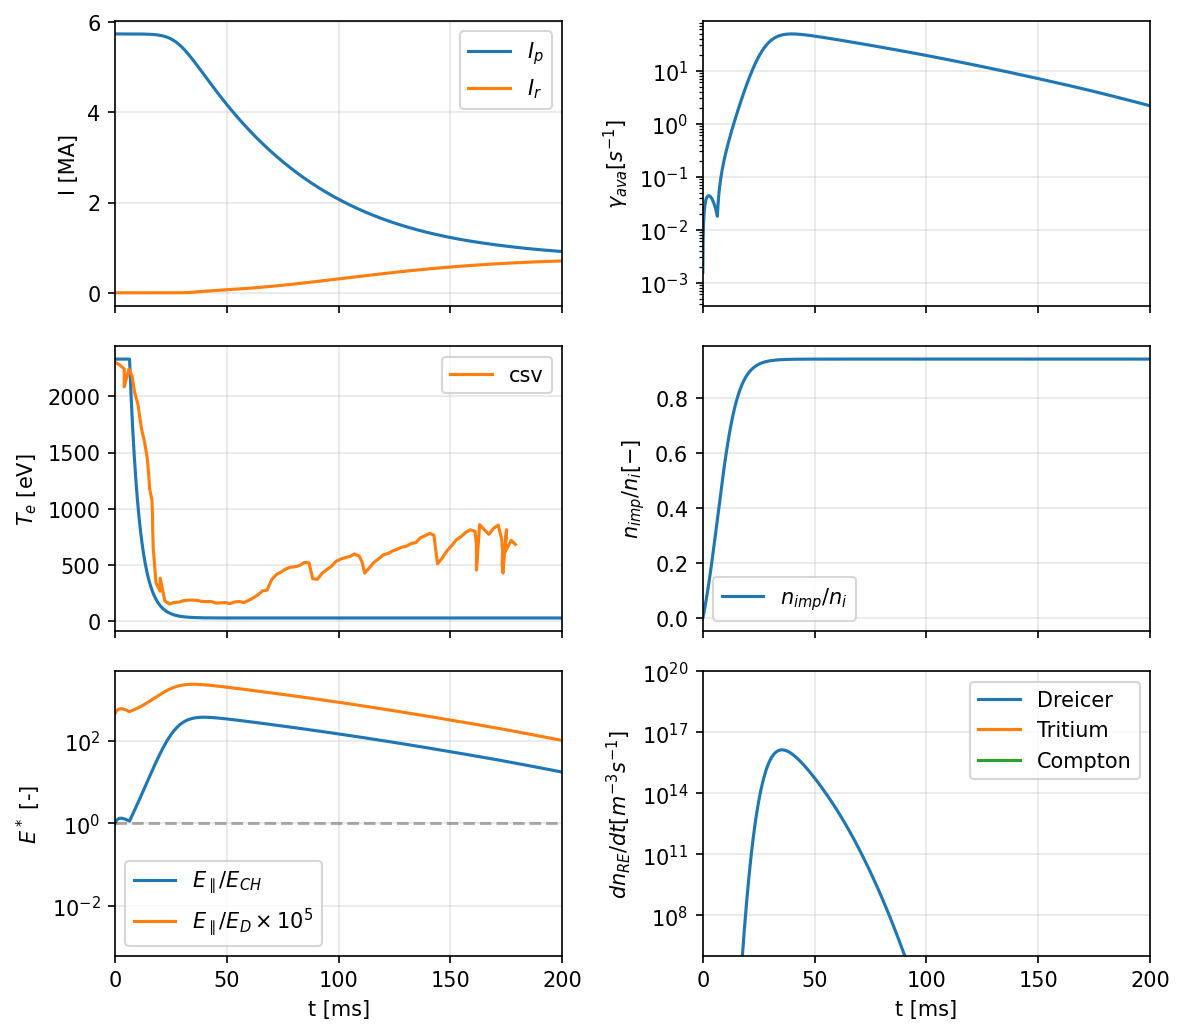

In [642]:

fig, axs = plt.subplots(3, 2, sharex=True, figsize=(8, 7), dpi=150)

# [0,0] Currents - Compare Plasma vs Runaway
axs[0, 0].plot(d['t'] * 1e3, Ip / 1e6, label='$I_p$')
axs[0, 0].plot(d['t'] * 1e3, Ir / 1e6, label='$I_r$')
axs[0, 0].set_ylabel('I [MA]')
axs[0, 0].legend()

# [1,0] Electron Temperature
axs[1, 0].plot(d['t'] * 1e3, d['Te'])
axs[1, 0].set_ylabel('$T_e$ [eV]')
#axs[1, 0].set_yscale('log')
data = np.loadtxt('Shot_20909_Temp.csv', delimiter=',')
#x = (data[:,0] -13.043814594603838)*1e3 
x = (data[:,0] -10.698039714569807)*1e3
#print(x[:5])
y = data[:,1]*1e3
axs[1, 0].plot(x, y, label="csv")
axs[1,0].legend()

# [2,0] Normalized Electric Fields
axs[2, 0].plot(d['t'] * 1e3, d['E_star'], label='$E_{\parallel}/E_{CH}$')
axs[2, 0].axhline(1, color='k', linestyle='--', alpha=0.3)
axs[2, 0].plot(d['t'] * 1e3, d['EoED'] * 1e5, label='$E_\parallel/E_D \\times 10^5$')
axs[2, 0].set_ylabel('$E^*$ [-]')
axs[2, 0].set_yscale('log')
axs[2, 0].legend()

 #[0,1] Avalanche Growth Rate
axs[0, 1].plot(d['t'] * 1e3, d['gamma_ava'])
axs[0, 1].set_ylabel('$\gamma_{ava} [s^{-1}]$')
axs[0, 1].set_yscale('log')

# [1,1] Critical Energy (Recalculated for visualization)
'''
from RE import getCriticalRunawayEnergy
import scipy.constants as const
Wc = getCriticalRunawayEnergy(d['E_star']) / const.eV
axs[1, 1].plot(d['t'] * 1e3, Wc / 1e3)
axs[1, 1].set_ylabel('$W_c$ [keV]')
axs[1, 1].set_yscale('log')
axs[1, 1].set_ylim([1e-1, 1e4])

'''
axs[1, 1].plot(d['t'] * 1e3, d['nimp'] / solver.ni, label='$n_{imp}/n_i$')
axs[1, 1].set_ylabel('$n_{imp}/n_i [-]$')
axs[1, 1].legend()

# [2,1] Primary Source Rates (Dreicer, Tritium, Compton)
axs[2, 1].plot(d['t'] * 1e3, d['SD'], label='Dreicer')
axs[2, 1].plot(d['t'] * 1e3, d['ST'], label='Tritium')
axs[2, 1].plot(d['t'] * 1e3, d['SC'], label='Compton')
axs[2, 1].set_ylabel('$dn_{RE}/dt [m^{-3}s^{-1}]$')
axs[2, 1].set_yscale('log')
axs[2, 1].set_ylim([1e6, 1e20])
axs[2, 1].legend()
'''
# [2,1] Primary Source Rates (Dreicer, Tritium, Compton)
axs[2, 1].plot(d['t'] * 1e3, d['ne']/d['ne'][0])
print("start: ",d['ne'][0], "Max during TQ: ", max(d['ne']), "Final taper:", d['ne'][-1])
axs[2, 1].set_xlabel('Time (ms)')
axs[2, 1].set_ylabel('ne/ne_0 (-)')
axs[2, 1].set_ylim(0, 15)
axs[2, 1].legend()
'''
#axs[2, 1].set_yscale('log')
#axs[2, 1].set_ylim([0, 1e19])
#axs[2, 1].legend()

for ax in axs.flat:
    ax.grid(True, alpha=0.3)
    #ax.set_xlim([0, d['t'].max() * 1e3])
    ax.set_xlim([0, 200])

axs[2, 0].set_xlabel('t [ms]')
axs[2, 1].set_xlabel('t [ms]')
plt.tight_layout()
plt.show()

0.7559745907266596


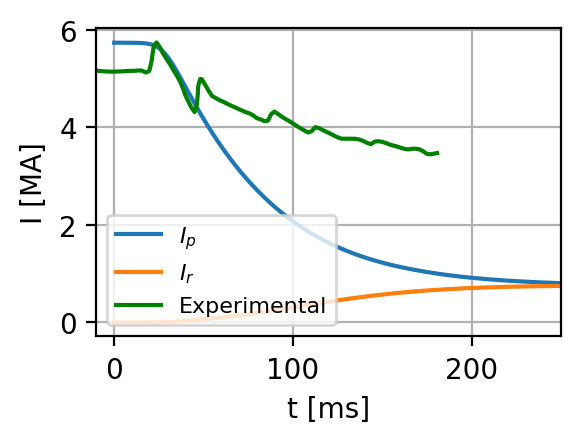

In [643]:
fig, axs = plt.subplots(1,1,figsize=(3,2),dpi=200,sharex=True)
plt.plot(t_sol*1e3,Ip/1e6,label='$I_p$')
plt.plot(t_sol*1e3,Ir/1e6,label='$I_r$')
print(Ir[-1]/1e6)
#plt.plot(t*1e3,Ir/1e6,label='$I_r$')
plt.grid()
plt.xlabel('t [ms]')
plt.ylabel('I [MA]')
#plt.ylim([4,6])
#plt.yticks(np.arange(0,13,2))
#plt.xlim([0,solver.tmax*1e3])
plt.xlim([-10,250])

data = np.loadtxt('Shot_20909_Current.csv', delimiter=',')
#x = (data[:,0] -13.05381319457121)*1e3
x = (data[:,0] -10.698362168801544)*1e3
y = data[:,1]
plt.plot(x, y, label='Experimental', color='g')

plt.legend(loc = 'lower left', fontsize=8)



Plateau Energy [MJ] = 4.519
Average RE Energy [MeV] = 96.350


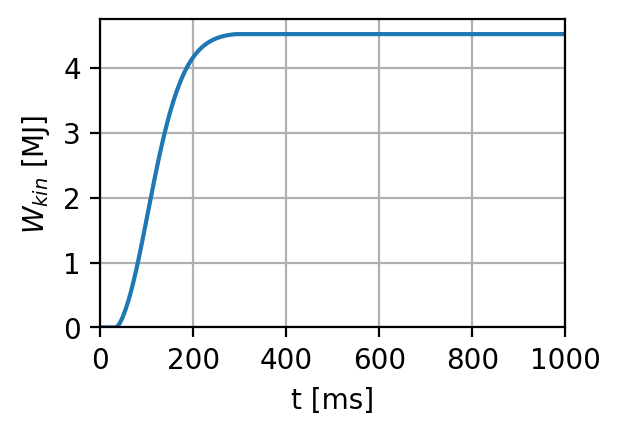

In [644]:
fig, axs = plt.subplots(1,1,figsize=(3,2),dpi=200,sharex=True)

plt.plot(t_sol*1e3,Wk/1e6)
plt.grid()
plt.xlabel('t [ms]')
plt.ylim(ymin=0)
plt.xlim([0,solver.tmax*1e3])
axs.set_ylabel('$W_{kin}$ [MJ]')


print('Plateau Energy [MJ] = %1.3f'%(Wk[-1]/1e6))

# Estimate the average RE energy in MeV
N = Ir[-1] * (2 * np.pi * solver.R0) / (const.e * const.c)
avg_energy = Wk[-1] / N
print('Average RE Energy [MeV] = %1.3f'%(avg_energy/1e6/const.eV))


## Shot 20803 (Be DN 2-stage)

In [278]:
def get_nimp_standalone(t, prescibe_nz_evolution=True, t0=3.5e-4, ni=1e19, n_imp=1e16):
    """
    Calculates impurity density evolution.
    t: time in seconds 
    """
    if prescibe_nz_evolution:
        

        n0, n1, n2 = -0.80, 0.36, 0.36
        #n0, n1, n2 = -20.27, 20.27, 20.27
        out = n0 + (n1-n0) * (1 + np.tanh((t-6.5e-3)/(t0))/2 + (n2 - n1) * (1 + np.tanh((t-40.71e-3)/(1*t0)))/2)
        return out * ni
    else:
        
        return n_imp * np.ones_like(t)

def get_custom_temp(t):
    """
    Custom piecewise temperature function matching the experimental trace.
    Includes a two-part linear recovery section between the valley and the second peak.
    """
    T_init = 480.0     # Initial core temp (eV)
    T_plat = 350.0     # Step plateau level
    T_min = 30.0       # Minimum floor
    T_mid = 180.0      # Kink
    T_peak2 = 380.0    # Secondary peak height
    T_final = 28.0     # Final background floor
    
    
    t_drop_end = 0.012
    t_mid = 0.015      
    t_peak2 = 0.04
    
    # Scalar Float Handler (for ODE Solver integration steps)
    if isinstance(t, (int, float, np.number)):
        if t < 0.00:
            return T_init
        elif t < 0.01:      
            return T_plat + (T_init - T_plat) * (1 - np.tanh((t - 0.002) / 0.001)) / 2
        elif t < t_drop_end:     
            return T_min + (T_plat - T_min) * (1 - np.tanh((t - 0.011) / 0.0005)) / 2
        elif t < t_mid:      
            # 1st Linear Segment: Steep jump from T_min to T_mid
            frac = (t - t_drop_end) / (t_mid - t_drop_end)
            return T_min + frac * (T_mid - T_min)
        elif t < t_peak2:
            # 2nd Linear Segment: Shallower rise from T_mid to T_peak2
            frac = (t - t_mid) / (t_peak2 - t_mid)
            return T_mid + frac * (T_peak2 - T_mid)
        else:
            return (T_peak2 - T_final) * np.exp(-(t - t_peak2) / 0.005) + T_final

    
    else:
        conds = [
            t < 0.00,
            (t >= 0.00) & (t < 0.01),
            (t >= 0.01) & (t < t_drop_end),
            (t >= t_drop_end) & (t < t_mid),
            (t >= t_mid) & (t < t_peak2),
            t >= t_peak2
        ]
        
        funcs = [
            lambda t: np.full_like(t, T_init),
            lambda t: T_plat + (T_init - T_plat) * (1 - np.tanh((t - 0.002) / 0.001)) / 2,
            lambda t: T_min + (T_plat - T_min) * (1 - np.tanh((t - 0.011) / 0.0005)) / 2,
            lambda t: T_min + ((t - t_drop_end) / (t_mid - t_drop_end)) * (T_mid - T_min),
            lambda t: T_mid + ((t - t_mid) / (t_peak2 - t_mid)) * (T_peak2 - T_mid),
            lambda t: (T_peak2 - T_final) * np.exp(-(t - t_peak2) / 0.005) + T_final
        ]
        
        return np.select(conds, [f(t) for f in funcs])

solver = solver0D()


solver.idiag = True 

solver.R0 = 2.96
solver.a = 1.25
solver.k = 1.6
solver.ni = 1.20e19
solver.Btor = 2.8
#solver.L = 6.95e-06
solver.L = 3.0e-06

solver.I0 = 3.28e6
solver.Ir0 = 0
solver.T0 = 2.33e3
solver.Tf = 30 
solver.t0 = 4.5e-3

solver.n_imp = 1e-11
#solver.n_imp = solver.ni * 5
solver.Z_imp = 4
solver.A_imp = 9
solver.tmax = 1000e-3
solver.tstart = 6.5e-3
solver.prescibe_nz_evolution = False
solver.iAvalanche = 3
solver.iDreicer = 2

solver.display()

solver.get_nimp = lambda t: get_nimp_standalone(
    t, 
    prescibe_nz_evolution=True, 
    t0=solver.t0 * 2,           
    ni=solver.ni,      
    n_imp=solver.n_imp         
)

solver.getTemp = get_custom_temp
t_sol, Ip, Ir, Wk = solver.solve()


d = solver.diag




 Constants:
Major radius R0 [m] = 2.960
Minor radius a [m] = 1.250
Elongation k [-] = 1.600
ni [per cubic m] = 1.2e+19
Inductance L [Henry] = 3e-06
Btor [Tesla] = 2.8

 Initial Values and TQ:
Init. Plasma Current I0 [A] = 3.28e+06
Init. RE Current Ir0 [A] = 0
Init. Temp. T0 [eV] = 2.33e+03
Final Temp. Tf [eV] = 30
Temp. decay time t0 [s] = 0.0045
Init. Vloop V0 [V] = 0
Final Vloop Vf [V] = 0

 Impurity Settings:
Added D density [per cubic m] = 1e-11
Added Impurity density [per cubic m] = 1e-11
Added Impurity Z, A [-] = 4, 9

 RE Source Settings: 

Primary: iDreicer = 2, iTritium = 0, iCompton = 0
Secondary: iAvalanche = 3

 Other Settings: 

tstart [s] = 0.0065
tmax [s] = 1
Zeff_scale [-] =1.0
device [-] = SPARC


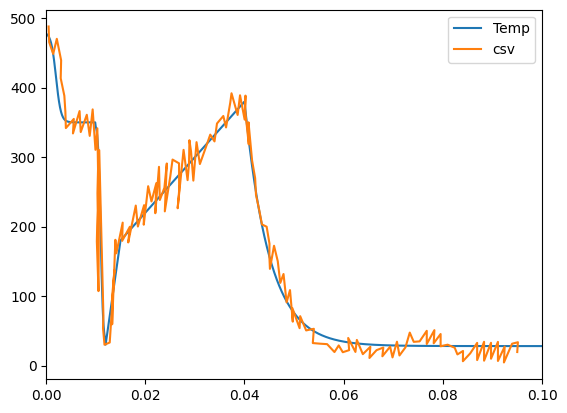

In [249]:
plt.plot(d['t'] , d['Te'], label = "Temp")
#axs[1, 0].set_ylabel('$T_e$ [eV]')
#axs[1, 0].set_yscale('log')
data = np.loadtxt('Shot_20803_Temp.csv', delimiter=',')
x = (data[:,0]-9) 
x = (data[:,0] -9)
#print(x[:5])
y = data[:,1]
plt.plot(x, y, label="csv")
plt.xlim([0,0.1])
plt.legend()

<>:22: SyntaxWarning: invalid escape sequence '\p'
<>:24: SyntaxWarning: invalid escape sequence '\p'
<>:31: SyntaxWarning: invalid escape sequence '\g'
<>:22: SyntaxWarning: invalid escape sequence '\p'
<>:24: SyntaxWarning: invalid escape sequence '\p'
<>:31: SyntaxWarning: invalid escape sequence '\g'
C:\Users\grace\AppData\Local\Temp\ipykernel_27336\4144010032.py:22: SyntaxWarning: invalid escape sequence '\p'
  axs[2, 0].plot(d['t'] * 1e3, d['E_star'], label='$E_{\parallel}/E_{CH}$')
C:\Users\grace\AppData\Local\Temp\ipykernel_27336\4144010032.py:24: SyntaxWarning: invalid escape sequence '\p'
  axs[2, 0].plot(d['t'] * 1e3, d['EoED'] * 1e5, label='$E_\parallel/E_D \\times 10^5$')
C:\Users\grace\AppData\Local\Temp\ipykernel_27336\4144010032.py:31: SyntaxWarning: invalid escape sequence '\g'
  axs[0, 1].set_ylabel('$\gamma_{ava} [s^{-1}]$')


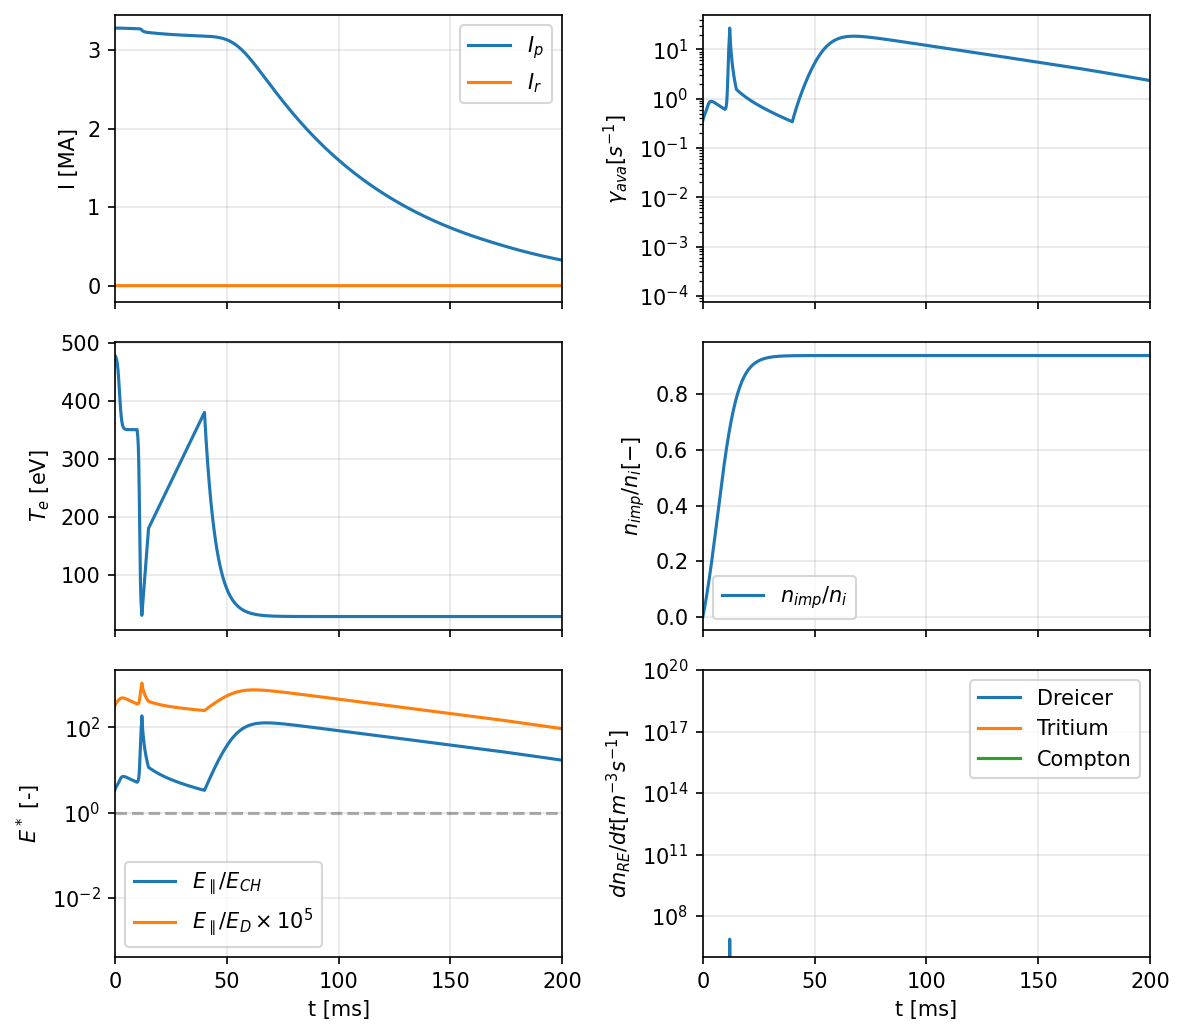

In [279]:

fig, axs = plt.subplots(3, 2, sharex=True, figsize=(8, 7), dpi=150)

# [0,0] Currents - Compare Plasma vs Runaway
axs[0, 0].plot(d['t'] * 1e3, Ip / 1e6, label='$I_p$')
axs[0, 0].plot(d['t'] * 1e3, Ir / 1e6, label='$I_r$')
axs[0, 0].set_ylabel('I [MA]')
axs[0, 0].legend()

# [1,0] Electron Temperature
axs[1, 0].plot(d['t'] * 1e3, d['Te'])
axs[1, 0].set_ylabel('$T_e$ [eV]')
#axs[1, 0].set_yscale('log')
#data = np.loadtxt('Shot_20909_Temp.csv', delimiter=',')
#x = (data[:,0] -13.043814594603838)*1e3 
#x = (data[:,0] -10.698039714569807)*1e3
#print(x[:5])
#y = data[:,1]*1e3
#axs[1, 0].plot(x, y, label="csv")
#axs[1,0].legend()

# [2,0] Normalized Electric Fields
axs[2, 0].plot(d['t'] * 1e3, d['E_star'], label='$E_{\parallel}/E_{CH}$')
axs[2, 0].axhline(1, color='k', linestyle='--', alpha=0.3)
axs[2, 0].plot(d['t'] * 1e3, d['EoED'] * 1e5, label='$E_\parallel/E_D \\times 10^5$')
axs[2, 0].set_ylabel('$E^*$ [-]')
axs[2, 0].set_yscale('log')
axs[2, 0].legend()

 #[0,1] Avalanche Growth Rate
axs[0, 1].plot(d['t'] * 1e3, d['gamma_ava'])
axs[0, 1].set_ylabel('$\gamma_{ava} [s^{-1}]$')
axs[0, 1].set_yscale('log')

# [1,1] Critical Energy (Recalculated for visualization)
'''
from RE import getCriticalRunawayEnergy
import scipy.constants as const
Wc = getCriticalRunawayEnergy(d['E_star']) / const.eV
axs[1, 1].plot(d['t'] * 1e3, Wc / 1e3)
axs[1, 1].set_ylabel('$W_c$ [keV]')
axs[1, 1].set_yscale('log')
axs[1, 1].set_ylim([1e-1, 1e4])

'''
axs[1, 1].plot(d['t'] * 1e3, d['nimp'] / solver.ni, label='$n_{imp}/n_i$')
axs[1, 1].set_ylabel('$n_{imp}/n_i [-]$')
axs[1, 1].legend()

# [2,1] Primary Source Rates (Dreicer, Tritium, Compton)
axs[2, 1].plot(d['t'] * 1e3, d['SD'], label='Dreicer')
axs[2, 1].plot(d['t'] * 1e3, d['ST'], label='Tritium')
axs[2, 1].plot(d['t'] * 1e3, d['SC'], label='Compton')
axs[2, 1].set_ylabel('$dn_{RE}/dt [m^{-3}s^{-1}]$')
axs[2, 1].set_yscale('log')
axs[2, 1].set_ylim([1e6, 1e20])
axs[2, 1].legend()
'''
# [2,1] Primary Source Rates (Dreicer, Tritium, Compton)
axs[2, 1].plot(d['t'] * 1e3, d['ne']/d['ne'][0])
print("start: ",d['ne'][0], "Max during TQ: ", max(d['ne']), "Final taper:", d['ne'][-1])
axs[2, 1].set_xlabel('Time (ms)')
axs[2, 1].set_ylabel('ne/ne_0 (-)')
axs[2, 1].set_ylim(0, 15)
axs[2, 1].legend()
'''
#axs[2, 1].set_yscale('log')
#axs[2, 1].set_ylim([0, 1e19])
#axs[2, 1].legend()

for ax in axs.flat:
    ax.grid(True, alpha=0.3)
    #ax.set_xlim([0, d['t'].max() * 1e3])
    ax.set_xlim([0, 200])

axs[2, 0].set_xlabel('t [ms]')
axs[2, 1].set_xlabel('t [ms]')
plt.tight_layout()
plt.show()

2.6554956719656947e-13


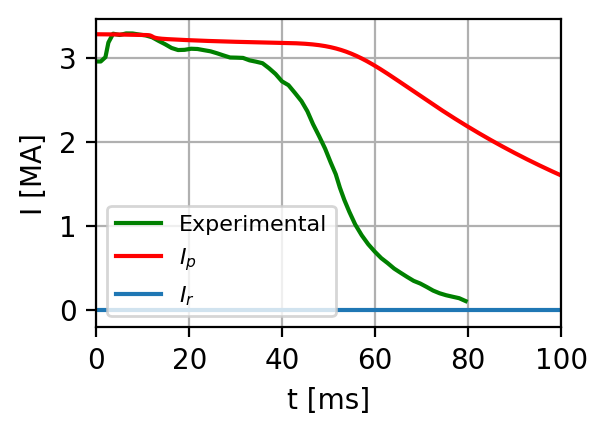

In [246]:
fig, axs = plt.subplots(1,1,figsize=(3,2),dpi=200,sharex=True)
data = np.loadtxt('Shot_20803_Current.csv', delimiter=',')
#x = (data[:,0] -13.05381319457121)*1e3
x = (data[:,0] -9.01)*1e3 #9.0178
y = data[:,1]
plt.plot(x, y, label='Experimental', color='g')
plt.plot(t_sol*1e3,Ip/1e6,label='$I_p$', color = 'r')
plt.plot(t_sol*1e3,Ir/1e6,label='$I_r$')
print(Ir[-1]/1e6)
#plt.plot(t*1e3,Ir/1e6,label='$I_r$')
plt.grid()
plt.xlabel('t [ms]')
plt.ylabel('I [MA]')
#plt.ylim([4,6])
#plt.yticks(np.arange(0,13,2))
#plt.xlim([0,solver.tmax*1e3])
plt.xlim([0,100])



plt.legend(loc = 'lower left', fontsize=8)



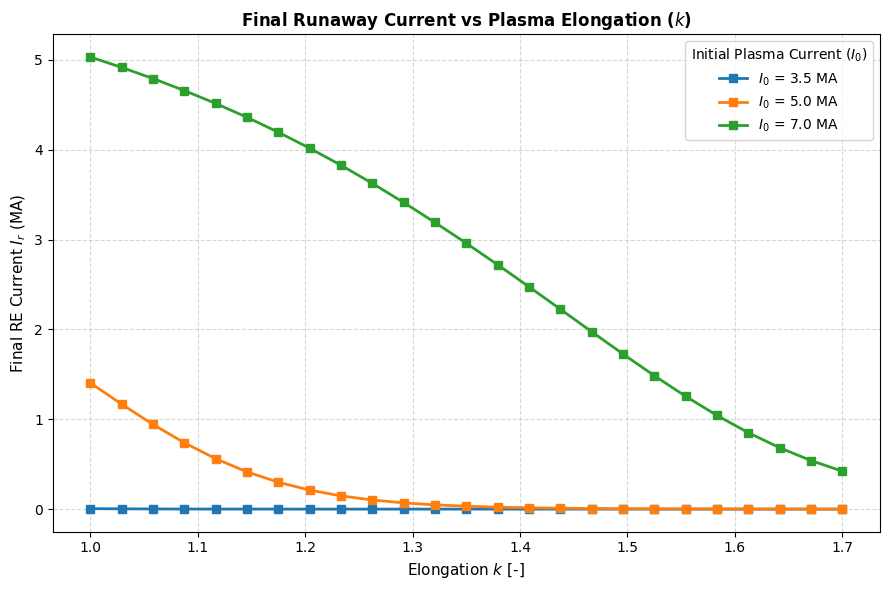

In [251]:

k_range = np.linspace(1, 1.7, 25)  
I0_values = [3.5e6, 5e6, 7e6]        

plt.figure(figsize=(9, 6))


for I0_val in I0_values:
    final_Ir_list = []
    
    
    for k_val in k_range:
        
        solver = solver0D()
        solver.idiag = True 
        
        
        solver.R0 = 2.96
        solver.a = 1.25
        solver.Btor = 2.8
        solver.L = 4.58e-06
        
        
        solver.I0 = I0_val
        solver.Ir0 = 0
        solver.T0 = 2.33e3
        solver.t0 = 4.5e-3
        solver.tmax = 200e-3
        solver.tstart = 3.5e-3
        
        solver.n_imp = 1e-11
        solver.Z_imp = 6
        solver.A_imp = 12
        solver.prescibe_nz_evolution = False
        solver.iAvalanche = 3
        solver.iDreicer = 2
        
        solver.ni = 1e19
        solver.k = k_val
        solver.Tf = 30
        
     
        solver.get_nimp = lambda t: get_nimp_standalone(
            t, 
            prescibe_nz_evolution=True, 
            t0=solver.t0 * 2,          
            ni=solver.ni,      
            n_imp=solver.n_imp         
        )
        solver.getTemp = get_custom_temp
        
        t_sol, Ip, Ir, Wk = solver.solve()
        
    
        final_Ir_list.append(Ir[-1] / 1e6) 
        

    plt.plot(k_range, final_Ir_list, marker='s', lw=2, label=f'$I_0$ = {I0_val/1e6} MA')

plt.title('Final Runaway Current vs Plasma Elongation ($k$)', fontsize=12, fontweight='bold')
plt.xlabel('Elongation $k$ [-]', fontsize=11)
plt.ylabel('Final RE Current $I_r$ (MA)', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(title='Initial Plasma Current ($I_0$)', loc='best')

plt.tight_layout()
plt.show()

## Shot 18189 (Carbon SN)

In [645]:
def get_nimp_standalone(t, prescibe_nz_evolution=True, t0=3.4e-4, ni=1e19, n_imp=1e16):
    """
    Calculates impurity density evolution.
    t: time in seconds 
    """
    if prescibe_nz_evolution:
        

        n0, n1, n2 = -0.48, 0.48, 0.48
        #n0, n1, n2 = -1.13, 1.13, 1.13
        out = n0 + (n1-n0) * (1 + np.tanh((t-3.5e-3)/(t0))/2 + (n2 - n1) * (1 + np.tanh((t-10.71e-3)/(1*t0)))/2)
        return out * ni
    else:
        
        return n_imp * np.ones_like(t)

solver = solver0D()


solver.idiag = True 

solver.R0 = 2.96
solver.a = 1.25
solver.k = 1.68
solver.ni = 0.99e19
solver.Btor = 2.8
#solver.L = 6.95e-06
solver.L = 5.00e-06

solver.I0 = 4.90e6
solver.Ir0 = 0
solver.T0 = 4.2e3
solver.Tf = 8.40
solver.t0 = 3.4e-4

solver.n_imp = 1e-11
#solver.n_imp = solver.ni * 5
solver.Z_imp = 6
solver.A_imp = 12
solver.tmax = 100e-3
solver.tstart = 3.5e-3
solver.prescibe_nz_evolution = False
solver.iAvalanche = 3
solver.iDreicer = 2

solver.display()

solver.get_nimp = lambda t: get_nimp_standalone(
    t, 
    prescibe_nz_evolution=True, 
    t0=solver.t0 * 2,           
    ni=solver.ni,      
    n_imp=solver.n_imp         
)


t_sol, Ip, Ir, Wk = solver.solve()


d = solver.diag


 Constants:
Major radius R0 [m] = 2.960
Minor radius a [m] = 1.250
Elongation k [-] = 1.680
ni [per cubic m] = 9.9e+18
Inductance L [Henry] = 5e-06
Btor [Tesla] = 2.8

 Initial Values and TQ:
Init. Plasma Current I0 [A] = 4.9e+06
Init. RE Current Ir0 [A] = 0
Init. Temp. T0 [eV] = 4.2e+03
Final Temp. Tf [eV] = 8.4
Temp. decay time t0 [s] = 0.00034
Init. Vloop V0 [V] = 0
Final Vloop Vf [V] = 0

 Impurity Settings:
Added D density [per cubic m] = 1e-11
Added Impurity density [per cubic m] = 1e-11
Added Impurity Z, A [-] = 6, 12

 RE Source Settings: 

Primary: iDreicer = 2, iTritium = 0, iCompton = 0
Secondary: iAvalanche = 3

 Other Settings: 

tstart [s] = 0.0035
tmax [s] = 0.1
Zeff_scale [-] =1.0
device [-] = SPARC


<>:22: SyntaxWarning: invalid escape sequence '\p'
<>:24: SyntaxWarning: invalid escape sequence '\p'
<>:31: SyntaxWarning: invalid escape sequence '\g'
<>:22: SyntaxWarning: invalid escape sequence '\p'
<>:24: SyntaxWarning: invalid escape sequence '\p'
<>:31: SyntaxWarning: invalid escape sequence '\g'
C:\Users\grace\AppData\Local\Temp\ipykernel_27336\33490027.py:22: SyntaxWarning: invalid escape sequence '\p'
  axs[2, 0].plot(d['t'] * 1e3, d['E_star'], label='$E_{\parallel}/E_{CH}$')
C:\Users\grace\AppData\Local\Temp\ipykernel_27336\33490027.py:24: SyntaxWarning: invalid escape sequence '\p'
  axs[2, 0].plot(d['t'] * 1e3, d['EoED'] * 1e5, label='$E_\parallel/E_D \\times 10^5$')
C:\Users\grace\AppData\Local\Temp\ipykernel_27336\33490027.py:31: SyntaxWarning: invalid escape sequence '\g'
  axs[0, 1].set_ylabel('$\gamma_{ava} [s^{-1}]$')


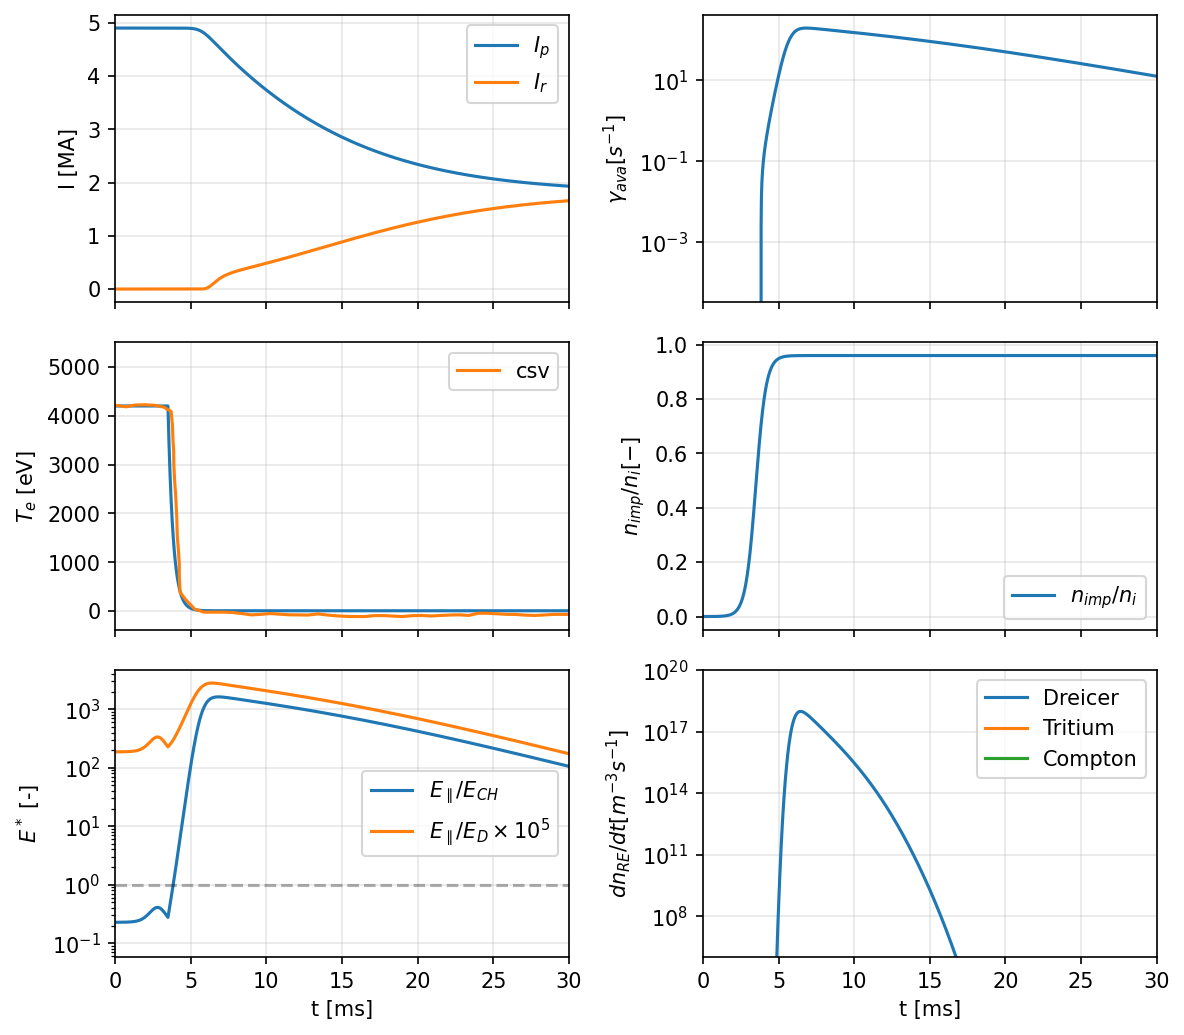

In [646]:
fig, axs = plt.subplots(3, 2, sharex=True, figsize=(8, 7), dpi=150)

# [0,0] Currents - Compare Plasma vs Runaway
axs[0, 0].plot(d['t'] * 1e3, Ip / 1e6, label='$I_p$')
axs[0, 0].plot(d['t'] * 1e3, Ir / 1e6, label='$I_r$')
axs[0, 0].set_ylabel('I [MA]')
axs[0, 0].legend()

# [1,0] Electron Temperature
axs[1, 0].plot(d['t'] * 1e3, d['Te'])
axs[1, 0].set_ylabel('$T_e$ [eV]')
#axs[1, 0].set_yscale('log')
data = np.loadtxt('Shot_18058_Temp.csv', delimiter=',')
#x = (data[:,0] -13.043814594603838)*1e3 
x = (data[:,0] -13.046834594603838)*1e3
#print(x[:5])
y = data[:,1]*1e3
axs[1, 0].plot(x, y, label="csv")
axs[1,0].legend()

# [2,0] Normalized Electric Fields
axs[2, 0].plot(d['t'] * 1e3, d['E_star'], label='$E_{\parallel}/E_{CH}$')
axs[2, 0].axhline(1, color='k', linestyle='--', alpha=0.3)
axs[2, 0].plot(d['t'] * 1e3, d['EoED'] * 1e5, label='$E_\parallel/E_D \\times 10^5$')
axs[2, 0].set_ylabel('$E^*$ [-]')
axs[2, 0].set_yscale('log')
axs[2, 0].legend()

# [0,1] Avalanche Growth Rate
axs[0, 1].plot(d['t'] * 1e3, d['gamma_ava'])
axs[0, 1].set_ylabel('$\gamma_{ava} [s^{-1}]$')
axs[0, 1].set_yscale('log')

# [1,1] Critical Energy (Recalculated for visualization)
'''
from RE import getCriticalRunawayEnergy
import scipy.constants as const
Wc = getCriticalRunawayEnergy(d['E_star']) / const.eV
axs[1, 1].plot(d['t'] * 1e3, Wc / 1e3)
axs[1, 1].set_ylabel('$W_c$ [keV]')
axs[1, 1].set_yscale('log')
axs[1, 1].set_ylim([1e-1, 1e4])

'''
axs[1, 1].plot(d['t'] * 1e3, d['nimp'] / solver.ni, label='$n_{imp}/n_i$')
axs[1, 1].set_ylabel('$n_{imp}/n_i [-]$')
axs[1, 1].legend()

# [2,1] Primary Source Rates (Dreicer, Tritium, Compton)
axs[2, 1].plot(d['t'] * 1e3, d['SD'], label='Dreicer')
axs[2, 1].plot(d['t'] * 1e3, d['ST'], label='Tritium')
axs[2, 1].plot(d['t'] * 1e3, d['SC'], label='Compton')
axs[2, 1].set_ylabel('$dn_{RE}/dt [m^{-3}s^{-1}]$')
axs[2, 1].set_yscale('log')
axs[2, 1].set_ylim([1e6, 1e20])
axs[2, 1].legend()
'''
# [2,1] Primary Source Rates (Dreicer, Tritium, Compton)
axs[2, 1].plot(d['t'] * 1e3, d['ne']/d['ne'][0])
print("start: ",d['ne'][0], "Max during TQ: ", max(d['ne']), "Final taper:", d['ne'][-1])
axs[2, 1].set_xlabel('Time (ms)')
axs[2, 1].set_ylabel('ne/ne_0 (-)')
axs[2, 1].set_ylim(0, 15)
axs[2, 1].legend()
'''
#axs[2, 1].set_yscale('log')
#axs[2, 1].set_ylim([0, 1e19])
#axs[2, 1].legend()

for ax in axs.flat:
    ax.grid(True, alpha=0.3)
    #ax.set_xlim([0, d['t'].max() * 1e3])
    ax.set_xlim([0, 30])

axs[2, 0].set_xlabel('t [ms]')
axs[2, 1].set_xlabel('t [ms]')
plt.tight_layout()
plt.show()

1.8013783115575537


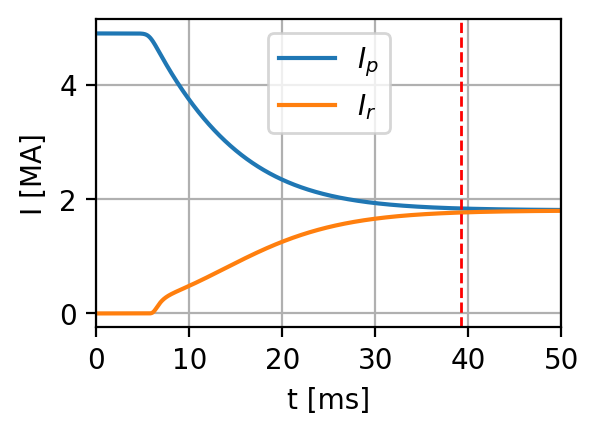

In [647]:
fig, axs = plt.subplots(1,1,figsize=(3,2),dpi=200,sharex=True)
plt.plot(t_sol*1e3,Ip/1e6,label='$I_p$')
print(Ip[-1]/1e6)
plt.plot(t_sol*1e3,Ir/1e6,label='$I_r$')
plt.axvline(x=11.9*3 + 3.5, color='r', linestyle='--', linewidth=1)
plt.grid()
plt.xlabel('t [ms]')
plt.ylabel('I [MA]')
#plt.ylim([0,5])
#plt.yticks(np.arange(0,13,2))
#plt.xlim([0,solver.tmax*1e3])
plt.xlim([0,50])

#data = np.loadtxt('Shot_19548_Current.csv', delimiter=',')
#x = (data[:,0] -13.05381319457121)*1e3
#x = (data[:,0] -13.355577873439327)*1e3
#y = data[:,1]
#plt.plot(x, y, label='CSV data', color='g')

plt.legend()


Plateau Energy [MJ] = 11.254
Average RE Energy [MeV] = 100.718


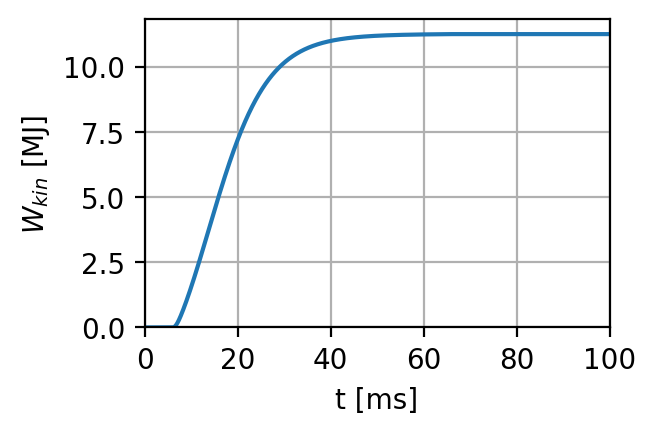

In [648]:
fig, axs = plt.subplots(1,1,figsize=(3,2),dpi=200,sharex=True)

plt.plot(t_sol*1e3,Wk/1e6)
plt.grid()
plt.xlabel('t [ms]')
plt.ylim(ymin=0)
plt.xlim([0,solver.tmax*1e3])
axs.set_ylabel('$W_{kin}$ [MJ]')


print('Plateau Energy [MJ] = %1.3f'%(Wk[-1]/1e6))

# Estimate the average RE energy in MeV
N = Ir[-1] * (2 * np.pi * solver.R0) / (const.e * const.c)
avg_energy = Wk[-1] / N
print('Average RE Energy [MeV] = %1.3f'%(avg_energy/1e6/const.eV))


## Shot 18684 (C SN)

In [649]:
def get_nimp_standalone(t, prescibe_nz_evolution=True, t0=3.4e-4, ni=1e19, n_imp=1e16):
    """
    Calculates impurity density evolution.
    t: time in seconds 
    """
    if prescibe_nz_evolution:
        

        #n0, n1, n2 = -0.47, 0.475, 0.47
        n0, n1, n2 = -0.54, 0.54, 0.54
        out = n0 + (n1-n0) * (1 + np.tanh((t-3.5e-3)/(t0))/2 + (n2 - n1) * (1 + np.tanh((t-10.71e-3)/(1*t0)))/2)
        return out * ni
    else:
        
        return n_imp * np.ones_like(t)

solver = solver0D()


solver.idiag = True 

solver.R0 = 2.96
solver.a = 1.25
solver.k = 1.7
solver.ni = 0.9e19
solver.Btor = 2.8
solver.L = 4.90e-06
#solver.L = 4.79e-06

solver.I0 = 5.68e6
solver.Ir0 = 0
solver.T0 = 4.2e3
solver.Tf = 10
solver.t0 = 3.4e-4

solver.n_imp = 1e-11
#solver.n_imp = solver.ni * 5
solver.Z_imp = 6
solver.A_imp = 12
solver.tmax = 100e-3
solver.tstart = 3.5e-3
solver.prescibe_nz_evolution = False
solver.iAvalanche = 3
solver.iDreicer = 2

solver.display()

solver.get_nimp = lambda t: get_nimp_standalone(
    t, 
    prescibe_nz_evolution=True, 
    t0=solver.t0 * 2,           
    ni=solver.ni,      
    n_imp=solver.n_imp         
)


t_sol, Ip, Ir, Wk = solver.solve()


d = solver.diag


 Constants:
Major radius R0 [m] = 2.960
Minor radius a [m] = 1.250
Elongation k [-] = 1.700
ni [per cubic m] = 9e+18
Inductance L [Henry] = 4.9e-06
Btor [Tesla] = 2.8

 Initial Values and TQ:
Init. Plasma Current I0 [A] = 5.68e+06
Init. RE Current Ir0 [A] = 0
Init. Temp. T0 [eV] = 4.2e+03
Final Temp. Tf [eV] = 10
Temp. decay time t0 [s] = 0.00034
Init. Vloop V0 [V] = 0
Final Vloop Vf [V] = 0

 Impurity Settings:
Added D density [per cubic m] = 1e-11
Added Impurity density [per cubic m] = 1e-11
Added Impurity Z, A [-] = 6, 12

 RE Source Settings: 

Primary: iDreicer = 2, iTritium = 0, iCompton = 0
Secondary: iAvalanche = 3

 Other Settings: 

tstart [s] = 0.0035
tmax [s] = 0.1
Zeff_scale [-] =1.0
device [-] = SPARC


<>:22: SyntaxWarning: invalid escape sequence '\p'
<>:24: SyntaxWarning: invalid escape sequence '\p'
<>:31: SyntaxWarning: invalid escape sequence '\g'
<>:22: SyntaxWarning: invalid escape sequence '\p'
<>:24: SyntaxWarning: invalid escape sequence '\p'
<>:31: SyntaxWarning: invalid escape sequence '\g'
C:\Users\grace\AppData\Local\Temp\ipykernel_27336\33490027.py:22: SyntaxWarning: invalid escape sequence '\p'
  axs[2, 0].plot(d['t'] * 1e3, d['E_star'], label='$E_{\parallel}/E_{CH}$')
C:\Users\grace\AppData\Local\Temp\ipykernel_27336\33490027.py:24: SyntaxWarning: invalid escape sequence '\p'
  axs[2, 0].plot(d['t'] * 1e3, d['EoED'] * 1e5, label='$E_\parallel/E_D \\times 10^5$')
C:\Users\grace\AppData\Local\Temp\ipykernel_27336\33490027.py:31: SyntaxWarning: invalid escape sequence '\g'
  axs[0, 1].set_ylabel('$\gamma_{ava} [s^{-1}]$')


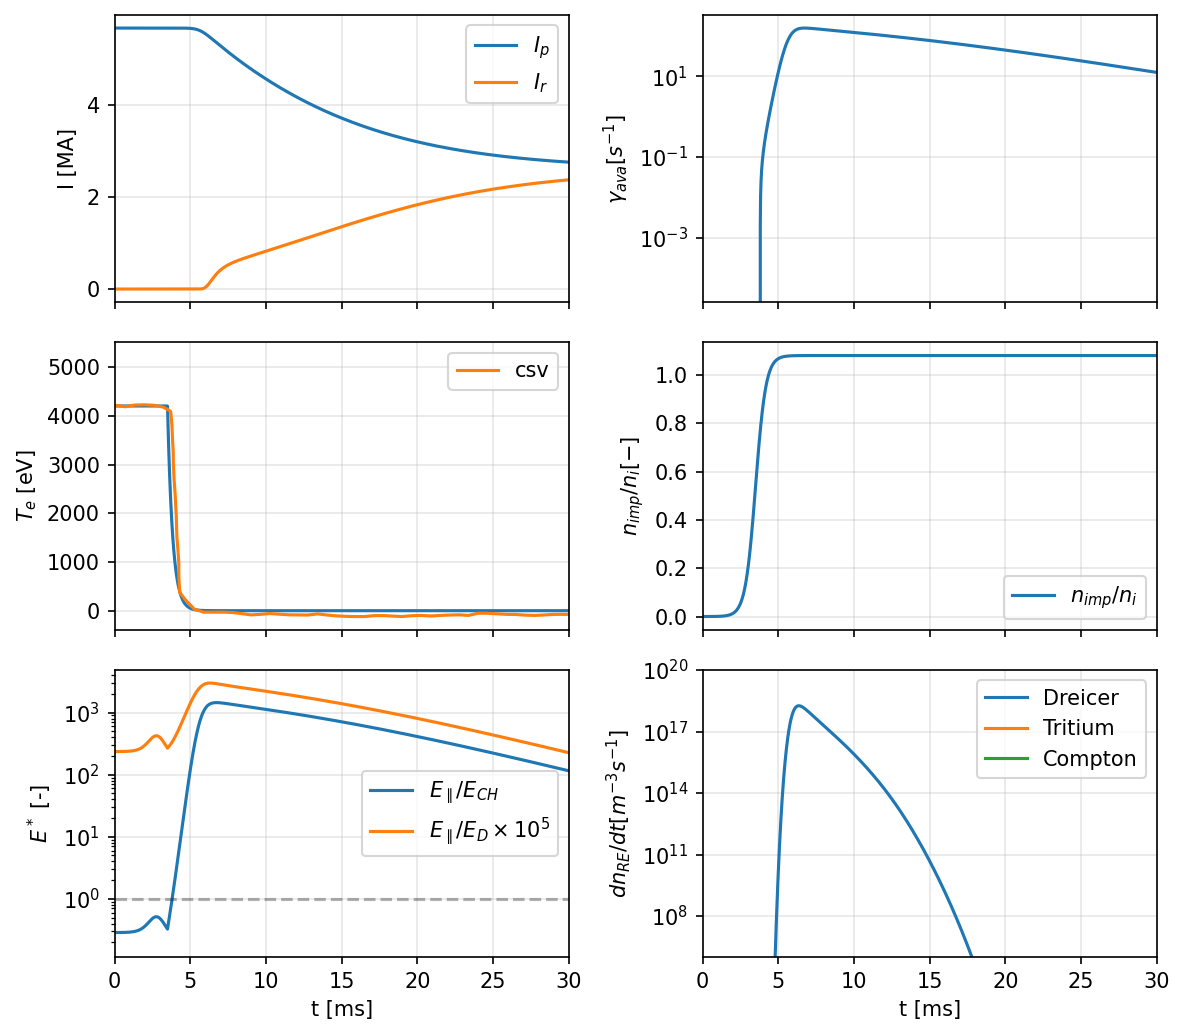

In [650]:
fig, axs = plt.subplots(3, 2, sharex=True, figsize=(8, 7), dpi=150)

# [0,0] Currents - Compare Plasma vs Runaway
axs[0, 0].plot(d['t'] * 1e3, Ip / 1e6, label='$I_p$')
axs[0, 0].plot(d['t'] * 1e3, Ir / 1e6, label='$I_r$')
axs[0, 0].set_ylabel('I [MA]')
axs[0, 0].legend()

# [1,0] Electron Temperature
axs[1, 0].plot(d['t'] * 1e3, d['Te'])
axs[1, 0].set_ylabel('$T_e$ [eV]')
#axs[1, 0].set_yscale('log')
data = np.loadtxt('Shot_18058_Temp.csv', delimiter=',')
#x = (data[:,0] -13.043814594603838)*1e3 
x = (data[:,0] -13.046834594603838)*1e3
#print(x[:5])
y = data[:,1]*1e3
axs[1, 0].plot(x, y, label="csv")
axs[1,0].legend()

# [2,0] Normalized Electric Fields
axs[2, 0].plot(d['t'] * 1e3, d['E_star'], label='$E_{\parallel}/E_{CH}$')
axs[2, 0].axhline(1, color='k', linestyle='--', alpha=0.3)
axs[2, 0].plot(d['t'] * 1e3, d['EoED'] * 1e5, label='$E_\parallel/E_D \\times 10^5$')
axs[2, 0].set_ylabel('$E^*$ [-]')
axs[2, 0].set_yscale('log')
axs[2, 0].legend()

# [0,1] Avalanche Growth Rate
axs[0, 1].plot(d['t'] * 1e3, d['gamma_ava'])
axs[0, 1].set_ylabel('$\gamma_{ava} [s^{-1}]$')
axs[0, 1].set_yscale('log')

# [1,1] Critical Energy (Recalculated for visualization)
'''
from RE import getCriticalRunawayEnergy
import scipy.constants as const
Wc = getCriticalRunawayEnergy(d['E_star']) / const.eV
axs[1, 1].plot(d['t'] * 1e3, Wc / 1e3)
axs[1, 1].set_ylabel('$W_c$ [keV]')
axs[1, 1].set_yscale('log')
axs[1, 1].set_ylim([1e-1, 1e4])

'''
axs[1, 1].plot(d['t'] * 1e3, d['nimp'] / solver.ni, label='$n_{imp}/n_i$')
axs[1, 1].set_ylabel('$n_{imp}/n_i [-]$')
axs[1, 1].legend()

# [2,1] Primary Source Rates (Dreicer, Tritium, Compton)
axs[2, 1].plot(d['t'] * 1e3, d['SD'], label='Dreicer')
axs[2, 1].plot(d['t'] * 1e3, d['ST'], label='Tritium')
axs[2, 1].plot(d['t'] * 1e3, d['SC'], label='Compton')
axs[2, 1].set_ylabel('$dn_{RE}/dt [m^{-3}s^{-1}]$')
axs[2, 1].set_yscale('log')
axs[2, 1].set_ylim([1e6, 1e20])
axs[2, 1].legend()
'''
# [2,1] Primary Source Rates (Dreicer, Tritium, Compton)
axs[2, 1].plot(d['t'] * 1e3, d['ne']/d['ne'][0])
print("start: ",d['ne'][0], "Max during TQ: ", max(d['ne']), "Final taper:", d['ne'][-1])
axs[2, 1].set_xlabel('Time (ms)')
axs[2, 1].set_ylabel('ne/ne_0 (-)')
axs[2, 1].set_ylim(0, 15)
axs[2, 1].legend()
'''
#axs[2, 1].set_yscale('log')
#axs[2, 1].set_ylim([0, 1e19])
#axs[2, 1].legend()

for ax in axs.flat:
    ax.grid(True, alpha=0.3)
    #ax.set_xlim([0, d['t'].max() * 1e3])
    ax.set_xlim([0, 30])

axs[2, 0].set_xlabel('t [ms]')
axs[2, 1].set_xlabel('t [ms]')
plt.tight_layout()
plt.show()

2.599521424702654


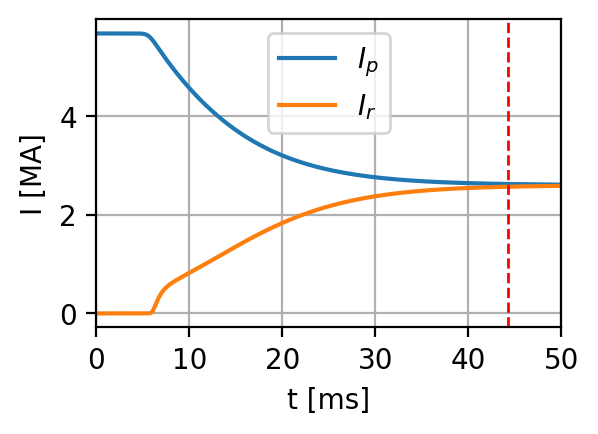

In [651]:
fig, axs = plt.subplots(1,1,figsize=(3,2),dpi=200,sharex=True)
plt.plot(t_sol*1e3,Ip/1e6,label='$I_p$')
print(Ip[-1]/1e6)
plt.plot(t_sol*1e3,Ir/1e6,label='$I_r$')
plt.axvline(x=13.6*3+3.5, color='r', linestyle='--', linewidth=1)
plt.grid()
plt.xlabel('t [ms]')
plt.ylabel('I [MA]')
#plt.ylim([0,5])
#plt.yticks(np.arange(0,13,2))
#plt.xlim([0,solver.tmax*1e3])
plt.xlim([0,50])

#data = np.loadtxt('Shot_19548_Current.csv', delimiter=',')
#x = (data[:,0] -13.05381319457121)*1e3
#x = (data[:,0] -13.355577873439327)*1e3
#y = data[:,1]
#plt.plot(x, y, label='CSV data', color='g')

plt.legend()


Plateau Energy [MJ] = 17.525
Average RE Energy [MeV] = 108.695


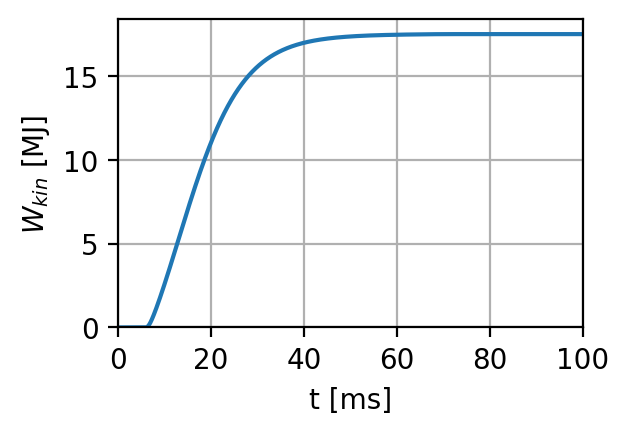

In [652]:
fig, axs = plt.subplots(1,1,figsize=(3,2),dpi=200,sharex=True)

plt.plot(t_sol*1e3,Wk/1e6)
plt.grid()
plt.xlabel('t [ms]')
plt.ylim(ymin=0)
plt.xlim([0,solver.tmax*1e3])
axs.set_ylabel('$W_{kin}$ [MJ]')


print('Plateau Energy [MJ] = %1.3f'%(Wk[-1]/1e6))

# Estimate the average RE energy in MeV
N = Ir[-1] * (2 * np.pi * solver.R0) / (const.e * const.c)
avg_energy = Wk[-1] / N
print('Average RE Energy [MeV] = %1.3f'%(avg_energy/1e6/const.eV))

## Shot 7718 (C lim)

In [653]:
def get_nimp_standalone(t, prescibe_nz_evolution=True, t0=3.4e-4, ni=1e19, n_imp=1e16):
    """
    Calculates impurity density evolution.
    t: time in seconds 
    """
    if prescibe_nz_evolution:
        

        n0, n1, n2 = -0.75, 0.75, 0.75
        #n0, n1, n2 = -1.13, 1.13, 1.13
        out = n0 + (n1-n0) * (1 + np.tanh((t-1e-3)/(t0))/2 + (n2 - n1) * (1 + np.tanh((t-10.71e-3)/(1*t0)))/2)
        return out * ni
    else:
        
        return n_imp * np.ones_like(t)

solver = solver0D()


solver.idiag = True 

solver.R0 = 2.96
solver.a = 1.25
solver.k = 1
solver.ni = 1e19
solver.Btor = 2.8
#solver.L = 6.95e-06
solver.L = 4.7e-06

solver.I0 = 4.21e6
solver.Ir0 = 0
solver.T0 = 4.2e3
solver.Tf = 6.7
solver.t0 = 3.4e-4

solver.n_imp = 1e-11
#solver.n_imp = solver.ni * 5
solver.Z_imp = 6
solver.A_imp = 12
solver.tmax = 100e-3
solver.tstart = 1e-3
solver.prescibe_nz_evolution = False
solver.iAvalanche = 3
solver.iDreicer = 2

solver.display()

solver.get_nimp = lambda t: get_nimp_standalone(
    t, 
    prescibe_nz_evolution=True, 
    t0=solver.t0 * 2,           
    ni=solver.ni,      
    n_imp=solver.n_imp         
)


t_sol, Ip, Ir, Wk = solver.solve()


d = solver.diag


 Constants:
Major radius R0 [m] = 2.960
Minor radius a [m] = 1.250
Elongation k [-] = 1.000
ni [per cubic m] = 1e+19
Inductance L [Henry] = 4.7e-06
Btor [Tesla] = 2.8

 Initial Values and TQ:
Init. Plasma Current I0 [A] = 4.21e+06
Init. RE Current Ir0 [A] = 0
Init. Temp. T0 [eV] = 4.2e+03
Final Temp. Tf [eV] = 6.7
Temp. decay time t0 [s] = 0.00034
Init. Vloop V0 [V] = 0
Final Vloop Vf [V] = 0

 Impurity Settings:
Added D density [per cubic m] = 1e-11
Added Impurity density [per cubic m] = 1e-11
Added Impurity Z, A [-] = 6, 12

 RE Source Settings: 

Primary: iDreicer = 2, iTritium = 0, iCompton = 0
Secondary: iAvalanche = 3

 Other Settings: 

tstart [s] = 0.001
tmax [s] = 0.1
Zeff_scale [-] =1.0
device [-] = SPARC


<>:22: SyntaxWarning: invalid escape sequence '\p'
<>:24: SyntaxWarning: invalid escape sequence '\p'
<>:31: SyntaxWarning: invalid escape sequence '\g'
<>:22: SyntaxWarning: invalid escape sequence '\p'
<>:24: SyntaxWarning: invalid escape sequence '\p'
<>:31: SyntaxWarning: invalid escape sequence '\g'
C:\Users\grace\AppData\Local\Temp\ipykernel_27336\3995016250.py:22: SyntaxWarning: invalid escape sequence '\p'
  axs[2, 0].plot(d['t'] * 1e3, d['E_star'], label='$E_{\parallel}/E_{CH}$')
C:\Users\grace\AppData\Local\Temp\ipykernel_27336\3995016250.py:24: SyntaxWarning: invalid escape sequence '\p'
  axs[2, 0].plot(d['t'] * 1e3, d['EoED'] * 1e5, label='$E_\parallel/E_D \\times 10^5$')
C:\Users\grace\AppData\Local\Temp\ipykernel_27336\3995016250.py:31: SyntaxWarning: invalid escape sequence '\g'
  axs[0, 1].set_ylabel('$\gamma_{ava} [s^{-1}]$')
C:\Users\grace\AppData\Local\Temp\ipykernel_27336\3995016250.py:19: UserWarning: No artists with labels found to put in legend.  Note that artis

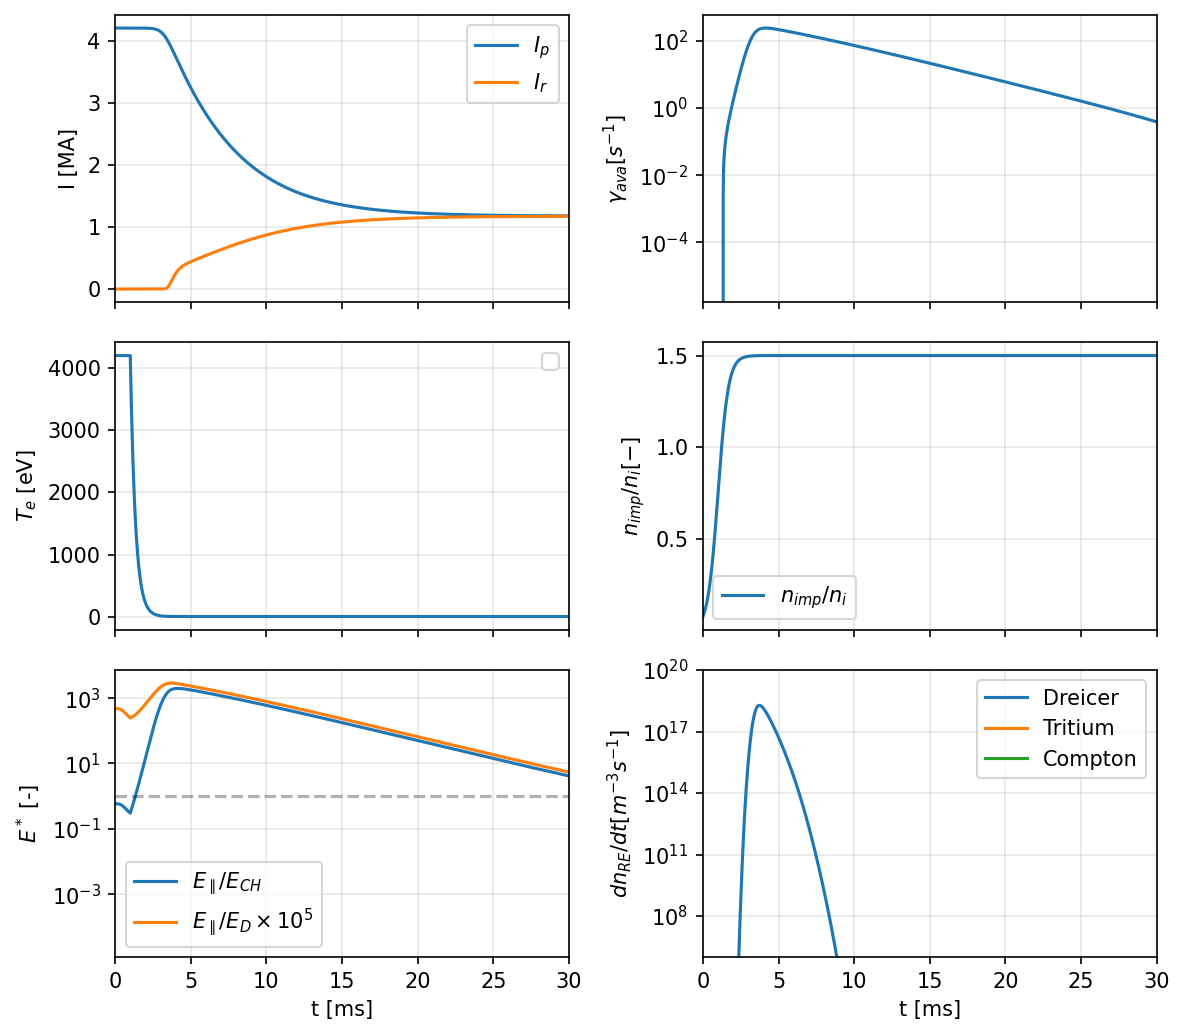

In [654]:
fig, axs = plt.subplots(3, 2, sharex=True, figsize=(8, 7), dpi=150)

# [0,0] Currents - Compare Plasma vs Runaway
axs[0, 0].plot(d['t'] * 1e3, Ip / 1e6, label='$I_p$')
axs[0, 0].plot(d['t'] * 1e3, Ir / 1e6, label='$I_r$')
axs[0, 0].set_ylabel('I [MA]')
axs[0, 0].legend()

# [1,0] Electron Temperature
axs[1, 0].plot(d['t'] * 1e3, d['Te'])
axs[1, 0].set_ylabel('$T_e$ [eV]')
#axs[1, 0].set_yscale('log')
data = np.loadtxt('Shot_18058_Temp.csv', delimiter=',')
#x = (data[:,0] -13.043814594603838)*1e3 
x = (data[:,0] -13.046834594603838)*1e3
#print(x[:5])
y = data[:,1]*1e3
#axs[1, 0].plot(x, y, label="csv")
axs[1,0].legend()

# [2,0] Normalized Electric Fields
axs[2, 0].plot(d['t'] * 1e3, d['E_star'], label='$E_{\parallel}/E_{CH}$')
axs[2, 0].axhline(1, color='k', linestyle='--', alpha=0.3)
axs[2, 0].plot(d['t'] * 1e3, d['EoED'] * 1e5, label='$E_\parallel/E_D \\times 10^5$')
axs[2, 0].set_ylabel('$E^*$ [-]')
axs[2, 0].set_yscale('log')
axs[2, 0].legend()

# [0,1] Avalanche Growth Rate
axs[0, 1].plot(d['t'] * 1e3, d['gamma_ava'])
axs[0, 1].set_ylabel('$\gamma_{ava} [s^{-1}]$')
axs[0, 1].set_yscale('log')

# [1,1] Critical Energy (Recalculated for visualization)
'''
from RE import getCriticalRunawayEnergy
import scipy.constants as const
Wc = getCriticalRunawayEnergy(d['E_star']) / const.eV
axs[1, 1].plot(d['t'] * 1e3, Wc / 1e3)
axs[1, 1].set_ylabel('$W_c$ [keV]')
axs[1, 1].set_yscale('log')
axs[1, 1].set_ylim([1e-1, 1e4])

'''
axs[1, 1].plot(d['t'] * 1e3, d['nimp'] / solver.ni, label='$n_{imp}/n_i$')
axs[1, 1].set_ylabel('$n_{imp}/n_i [-]$')
axs[1, 1].legend()

# [2,1] Primary Source Rates (Dreicer, Tritium, Compton)
axs[2, 1].plot(d['t'] * 1e3, d['SD'], label='Dreicer')
axs[2, 1].plot(d['t'] * 1e3, d['ST'], label='Tritium')
axs[2, 1].plot(d['t'] * 1e3, d['SC'], label='Compton')
axs[2, 1].set_ylabel('$dn_{RE}/dt [m^{-3}s^{-1}]$')
axs[2, 1].set_yscale('log')
axs[2, 1].set_ylim([1e6, 1e20])
axs[2, 1].legend()
'''
# [2,1] Primary Source Rates (Dreicer, Tritium, Compton)
axs[2, 1].plot(d['t'] * 1e3, d['ne']/d['ne'][0])
print("start: ",d['ne'][0], "Max during TQ: ", max(d['ne']), "Final taper:", d['ne'][-1])
axs[2, 1].set_xlabel('Time (ms)')
axs[2, 1].set_ylabel('ne/ne_0 (-)')
axs[2, 1].set_ylim(0, 15)
axs[2, 1].legend()
'''
#axs[2, 1].set_yscale('log')
#axs[2, 1].set_ylim([0, 1e19])
#axs[2, 1].legend()

for ax in axs.flat:
    ax.grid(True, alpha=0.3)
    #ax.set_xlim([0, d['t'].max() * 1e3])
    ax.set_xlim([0, 30])

axs[2, 0].set_xlabel('t [ms]')
axs[2, 1].set_xlabel('t [ms]')
plt.tight_layout()
plt.show()

1.1738822451133029


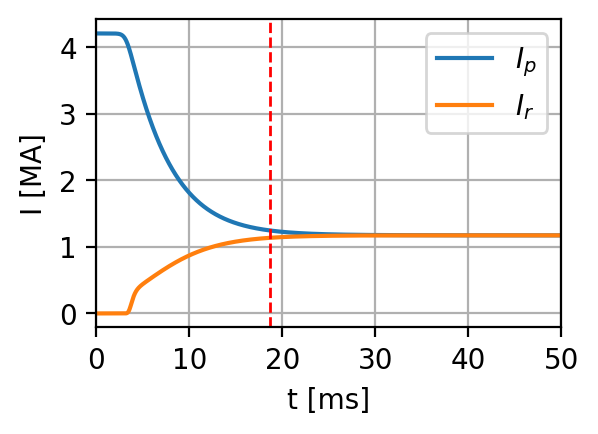

In [655]:
fig, axs = plt.subplots(1,1,figsize=(3,2),dpi=200,sharex=True)
plt.plot(t_sol*1e3,Ip/1e6,label='$I_p$')
print(Ip[-1]/1e6)
plt.plot(t_sol*1e3,Ir/1e6,label='$I_r$')
plt.axvline(x=5.9*3 + 1, color='r', linestyle='--', linewidth=1)
plt.grid()
plt.xlabel('t [ms]')
plt.ylabel('I [MA]')
#plt.ylim([0,5])
#plt.yticks(np.arange(0,13,2))
#plt.xlim([0,solver.tmax*1e3])
plt.xlim([0,50])

#data = np.loadtxt('Shot_19548_Current.csv', delimiter=',')
#x = (data[:,0] -13.05381319457121)*1e3
#x = (data[:,0] -13.355577873439327)*1e3
#y = data[:,1]
#plt.plot(x, y, label='CSV data', color='g')

plt.legend()


Plateau Energy [MJ] = 8.360
Average RE Energy [MeV] = 114.792


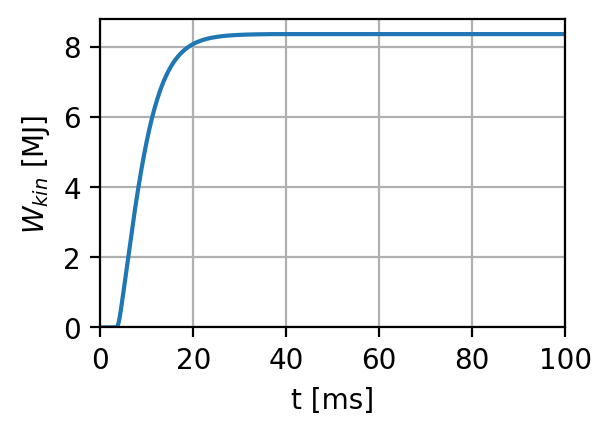

In [656]:
fig, axs = plt.subplots(1,1,figsize=(3,2),dpi=200,sharex=True)

plt.plot(t_sol*1e3,Wk/1e6)
plt.grid()
plt.xlabel('t [ms]')
plt.ylim(ymin=0)
plt.xlim([0,solver.tmax*1e3])
axs.set_ylabel('$W_{kin}$ [MJ]')


print('Plateau Energy [MJ] = %1.3f'%(Wk[-1]/1e6))

# Estimate the average RE energy in MeV
N = Ir[-1] * (2 * np.pi * solver.R0) / (const.e * const.c)
avg_energy = Wk[-1] / N
print('Average RE Energy [MeV] = %1.3f'%(avg_energy/1e6/const.eV))